In [1]:
import marimo as mo

# 00 - Setup

Load Persona-E2. Run checks. Build `events.parquet`.

In [2]:
# SETUP:
from personality import data

RAW = data.load_raw()
PROFILES = data.load_profiles()
GROUPS = data.load_group_consensus()

## Checks

In [3]:
CHECKS = data.check_events(RAW, PROFILES, groups=GROUPS)

In [4]:
CHECKS

,check,value
0,events rows,3113
1,profiles rows,36
2,empty english_item,0
3,english_item shorter than 5 chars,0
4,emotion labels found,"['anger', 'disgust', 'fear', 'joy', 'nan', 'ne..."
5,distinct label count,8
6,null confidences (total),73
7,reactions per annotator: min / median / max,3110 / 3111.0 / 3111
8,group consensus rows,3111


## Build `events.parquet`

In [5]:
EVENTS = data.build_events(RAW)
data.save_events(EVENTS)
EVENTS.shape

(3113, 76)

## Notes

- Raw file has 3,113 events, paper says 3,111. Two extra rows. Keep them.
- `nan` among emotion labels = skipped reactions by some annotators.
- `events.parquet` = wide format, one row per event.

# 01 - Speaker stats (Task 1)

Rule A = each person's pile = the events that made them feel
something. Text column: `english_item`.

In [6]:
# SETUP:
import pandas as pd
import matplotlib.pyplot as plt
from personality import counting

SPEAKERS = data.load_speakers()
PROFILES = data.load_profiles()

## The five counts, per speaker

One row = one speaker (E1-E36). Counts span all their texts.

- **vocabulary_size**: how many *different* words they used
  (words counted in their base form: "agreed" counts as "agree").
- **tokens**: how many words in total.
- **repetitions**: how many times a word is *reused inside one text*.
  A text with 30 words and 25 different ones repeats 5.
- **yes_words**: agree-words (yes, OK, sure…), counted by our frozen
  list.
- **no_words**: negation words (no, not, never…), same list idea.

Right side = their personality scores (0-1), from the dataset.

In [7]:
T1_ROWS = {
    name: counting.speaker_stats(pile["english_item"])
    for name, pile in SPEAKERS.groupby("annotator")
}
# rows become speakers; drop the unshown set column; keep whole numbers
T1_STATS = pd.DataFrame(T1_ROWS).T.drop(columns="vocabulary_set").astype(int)
T1_TRAIT_COLS = ["Open.", "Cons.", "Extra.", "Agree.", "Neuro."]
T1_TRAIT_NAMES = ["openness", "conscientiousness", "extraversion",
               "agreeableness", "neuroticism"]
T1_TRAITS = (PROFILES.set_index("ID")[T1_TRAIT_COLS]
          .rename(columns=dict(zip(T1_TRAIT_COLS, T1_TRAIT_NAMES))))
T1_JOINED = T1_STATS.join(T1_TRAITS)
T1_STATS.to_csv("outputs/tables/task1_speaker_stats.csv")

T1_JOINED

,vocabulary_size,tokens,repetitions,yes_words,no_words,openness,conscientiousness,extraversion,agreeableness,neuroticism
E1,9710,167235,54784,236,2327,0.698,0.646,0.604,0.740,0.417
E10,8234,124707,39954,188,1753,0.781,0.573,0.396,0.854,0.844
E11,7905,119497,39189,173,1653,0.760,0.781,0.646,0.802,0.188
E12,8179,129046,42268,191,1853,0.344,0.531,0.646,0.604,0.594
E13,9548,159321,51706,215,2156,0.562,0.625,0.625,0.573,0.448
E14,9063,151146,51045,230,2128,0.865,0.906,0.583,0.604,0.396
E15,8629,139869,45429,201,1965,0.698,0.562,0.583,0.875,0.552
E16,8873,145411,48255,213,2014,0.677,0.844,0.656,0.833,0.198
E17,9601,162863,53055,230,2269,0.625,0.552,0.427,0.510,0.844
E18,8429,129326,42361,171,1756,0.760,0.906,0.667,0.792,0.177


**What the table says:** speakers differ most in their *pile*, not in
their words.

- Vocabulary size sits in a tight band: 7.5k-9.7k different words
  (~15% spread)
  across all 36 people.
- Tokens: 104k-167k (~30% spread). This follows from pile size:
  how many stories made them feel something.
- Repetitions: ~45.7k of ~139k tokens. About a third of every pile is
  words said again inside the same text (mostly small common words).
- Confirmations are rare: ~199 yes-words vs ~1,928 no-words per pile,
  a ~10:1 gap in every speaker.

Word habits barely differ. Any personality signal lives in the small
variations. See the tie table.

## Evolution: repetitions, yes-words, no-words vs tokens

Each small panel = one speaker. The lines are "how many by now?"
counters: we walk through their texts in reading order, and at 10
stops along the way we note the total reached so far.

- x axis = words read so far.
- y axis = repetitions / negations / confirmations accumulated so far.

How to read it:

- A straight rising line = the habit is *constant*.
- A curve or jump = the habit changed somewhere along the pile.
- Compare speakers by **slope**, not by height: a bigger pile just
  makes a longer line.

What the task wants to see: do the habits *change* as more words are
used? Below: they barely do. All lines look straight.

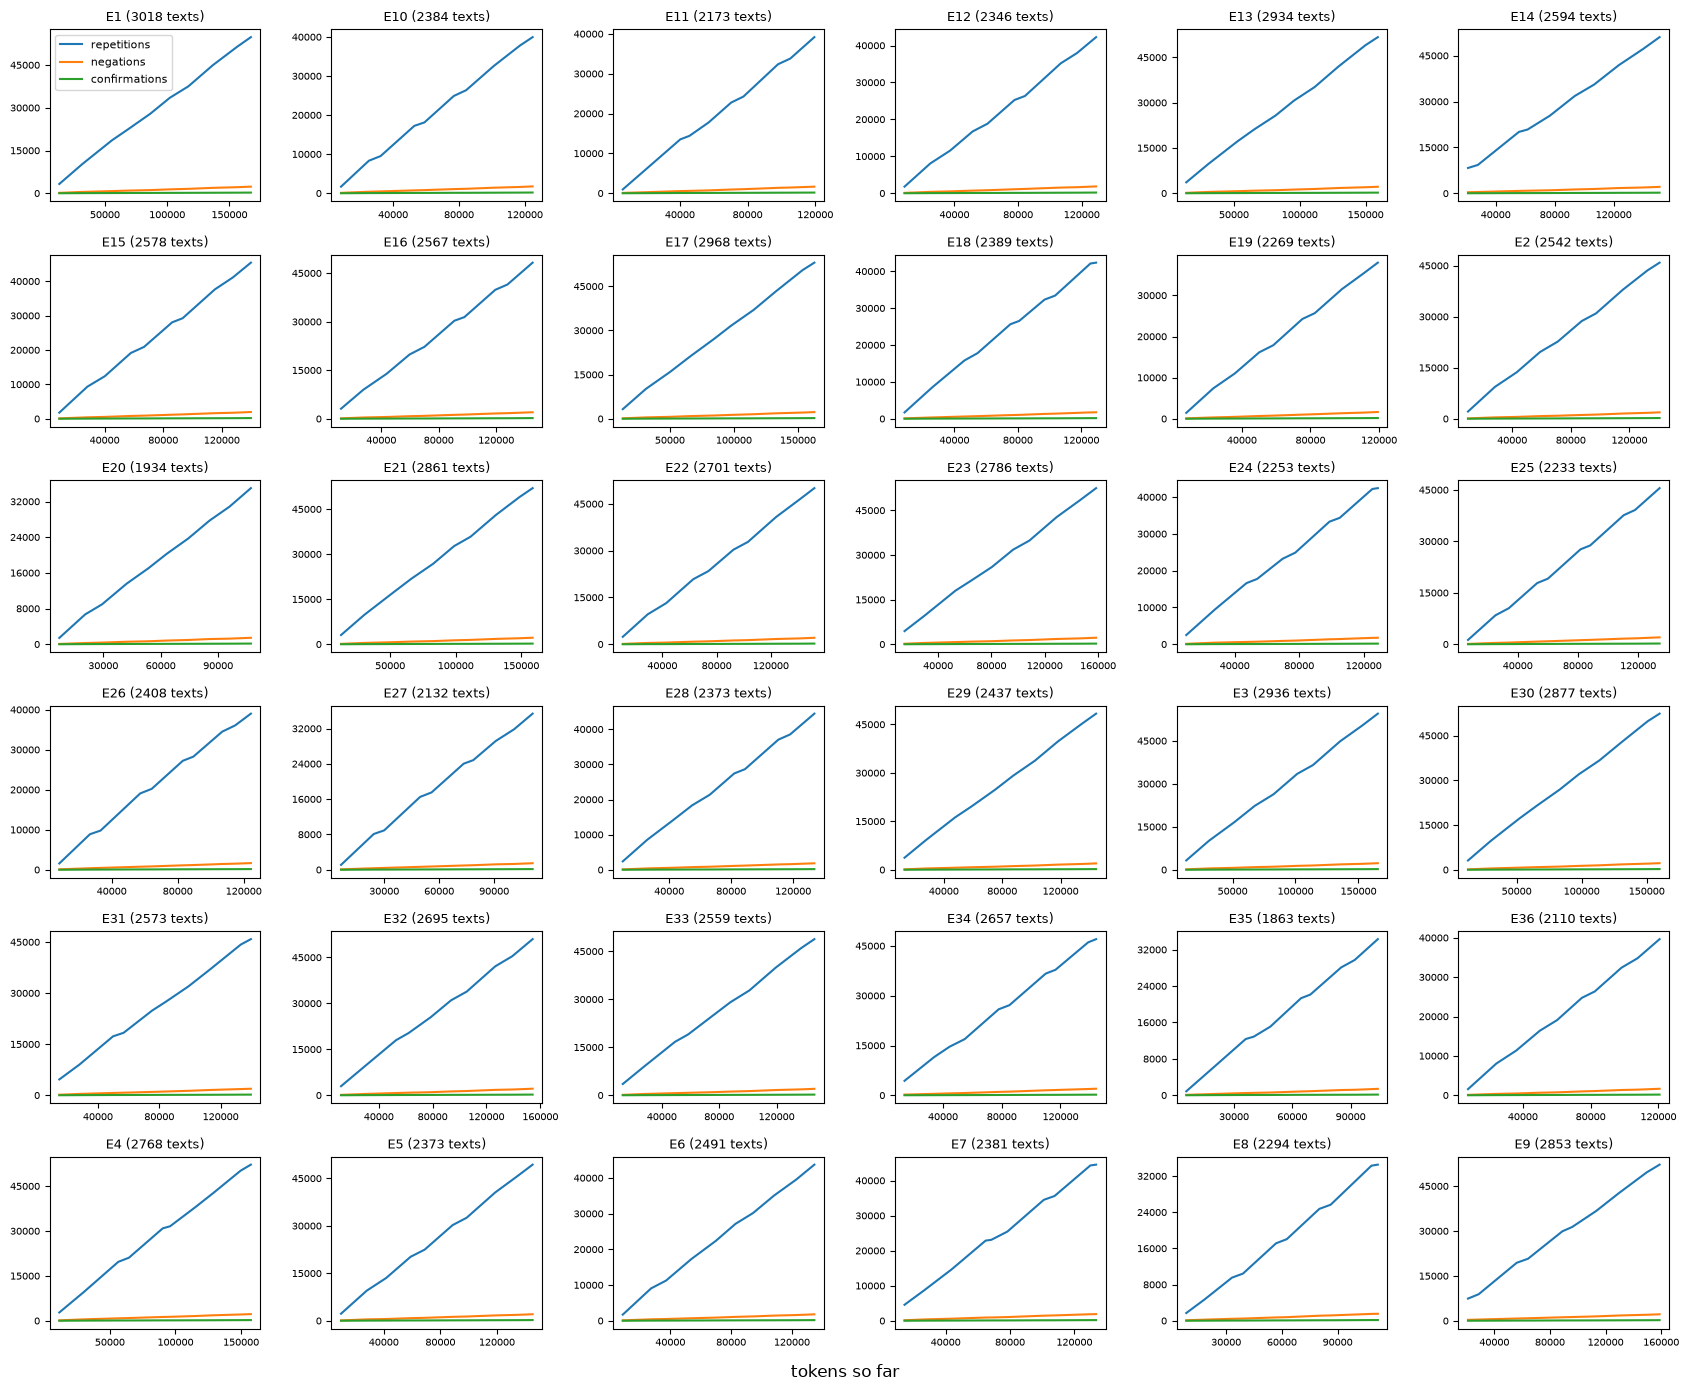

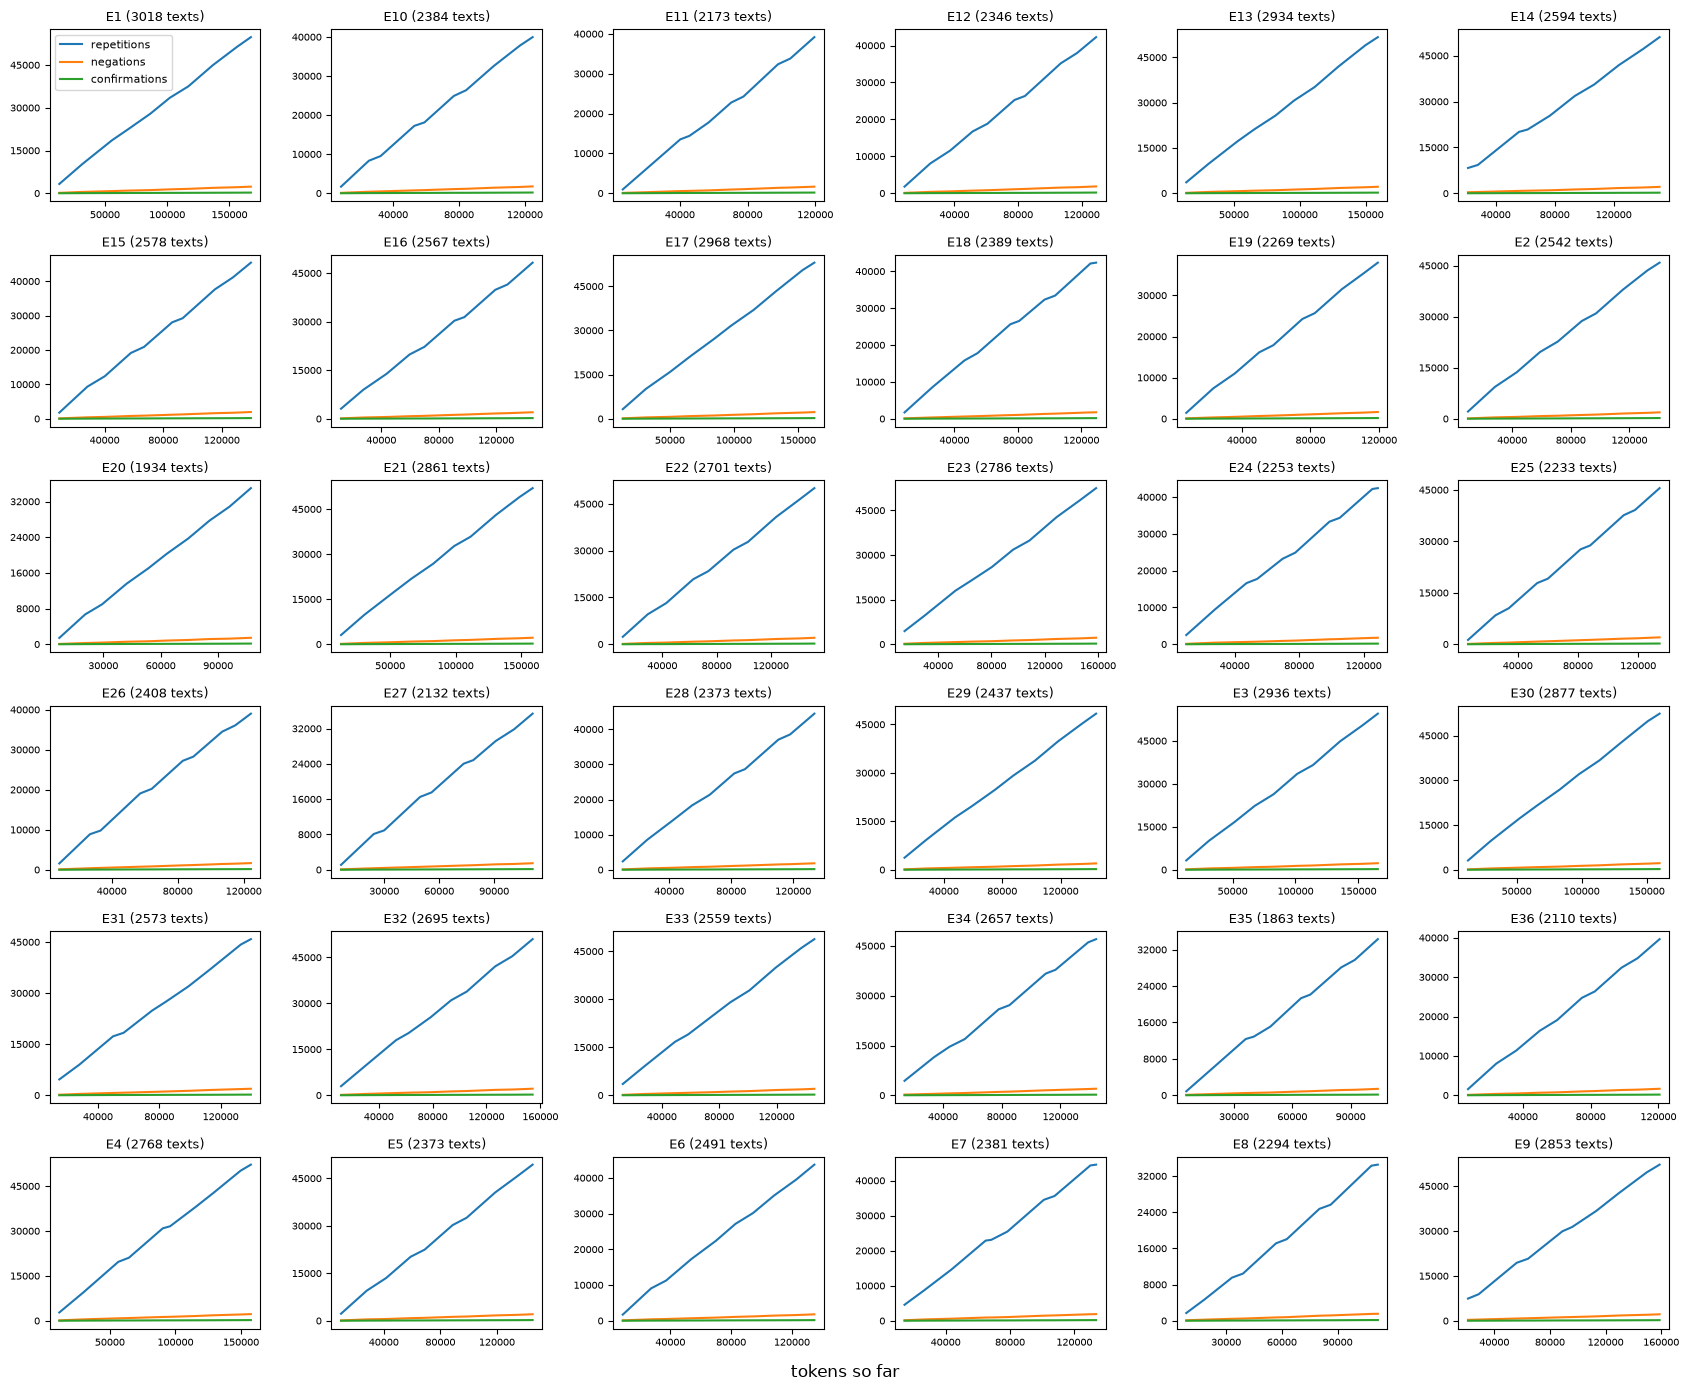

In [8]:
from matplotlib.ticker import MaxNLocator

T1_FIG, T1_AXES = plt.subplots(6, 6, figsize=(17, 14), sharex=False)
for _ax1, (_name, _pile) in zip(T1_AXES.flat, SPEAKERS.groupby("annotator")):
    _series = counting.chunked_series(_pile["english_item"], chunks=10)
    _ax1.plot(_series["tokens"], _series["repetitions"], label="repetitions")
    _ax1.plot(_series["tokens"], _series["no_words"], label="negations")
    _ax1.plot(_series["tokens"], _series["yes_words"], label="confirmations")
    _ax1.set_title(f"{_name} ({int(_pile.shape[0])} texts)", fontsize=9)
    _ax1.tick_params(labelsize=7)
    _ax1.xaxis.set_major_locator(MaxNLocator(4))
    _ax1.yaxis.set_major_locator(MaxNLocator(5))
# wipe the panel labels (the shared supxlabel carries them)
for _ax2 in T1_AXES.flat:
    _ax2.set_xlabel("")
    _ax2.set_ylabel("")
T1_AXES[0, 0].legend(fontsize=8)
T1_FIG.supxlabel("tokens so far")
T1_FIG.tight_layout()
T1_FIG.savefig("outputs/figures/task1_evolution.png", dpi=150)

T1_FIG

**What the grid says:** word habits do not change over the pile.

- Every line is near-straight: repetitions, negations and confirmations
  accumulate at a constant rate from the first text to the last.
- The small bends come from chunk boundaries landing between texts
  (texts are not equal-length), not from behavior changes.
- Meaning: nobody "warms up" or "cools down" mid-pile. Differences
  between people, if any, are *level* differences (slope), not
  changes along the way.

## Personality (annotator BFI, 0-1)

A **correlation table**. The question: *when a personality score is
high, does a word count also tend to be high?* Cells go from -1
to +1: +1 = the two rise together, 0 = no link, -1 = one rises
while the other falls. Method = Spearman (compares rank order,
not raw size).

Example reading: neuroticism × yes_words = 0.21, so slightly
emotional speakers use slightly more agree-words. Weak.

In [9]:
T1_CORR = (T1_JOINED[["tokens", "vocabulary_size", "repetitions", "yes_words",
                "no_words"] + T1_TRAIT_NAMES]
        .corr(method="spearman")
        .loc[T1_TRAIT_NAMES, ["tokens", "vocabulary_size", "repetitions",
                           "yes_words", "no_words"]])
T1_CORR.round(3).to_csv("outputs/tables/task1_trait_correlations.csv")
T1_CORR.round(2)

,tokens,vocabulary_size,repetitions,yes_words,no_words
openness,0.07,0.01,0.08,0.13,0.08
conscientiousness,0.01,0.01,0.03,-0.03,0.04
extraversion,-0.16,-0.14,-0.18,-0.22,-0.16
agreeableness,-0.14,-0.14,-0.16,-0.18,-0.15
neuroticism,0.16,0.15,0.14,0.21,0.14


**What the correlation table says:** the only visible ties are one-
directional and weak.

- Neuroticism: + with all five counts (0.14-0.21). Reading: more
  emotional people qualify *more* events (bigger piles, Rule A
  effect) and use slightly more yes-words and no-words per event.
- Extraversion and agreeableness: small negatives (−0.14 to −0.22).
- Openness and conscientiousness: ≈ 0. No link with these counts.

Magnitude check: max |r| = 0.22 at n = 36 is within chance range.
Treat every number as a direction, not an effect.

## Task 1 verdict

Word habits are nearly the same across the 36 speakers. Pile size is
the real differentiator, and it partly tracks neuroticism (a Rule A
side effect). Weak support, then, for "word habits show personality".
The texts are also the events' words, not the speakers' own. n = 36.

## Outputs

- `outputs/tables/task1_speaker_stats.csv`: the five counts per speaker
- `outputs/tables/task1_trait_correlations.csv`: Spearman table
- `outputs/figures/task1_evolution.png`: the 36-panel evolution plot

# 02 - Topic change (Task 2)

Hypothesis: people who change topics introduce new words fast and
have more topic piles.

In [10]:
# SETUP:
from personality import topics

SPEAKERS = data.load_speakers()
PROFILES = data.load_profiles()

## (a) Vocabulary growth vs tokens

"How many new words by now?" Each curve = one speaker, measured at
10 stops along their pile.

- **Left panel:** raw counts. Every speaker climbs from 0 to their
  vocabulary size; curves differ mainly in length (pile size).
- **Right panel:** same curve, x = fraction of their pile. A curve
  still rising at the end = new words keep coming = the
  topic-changer pattern.

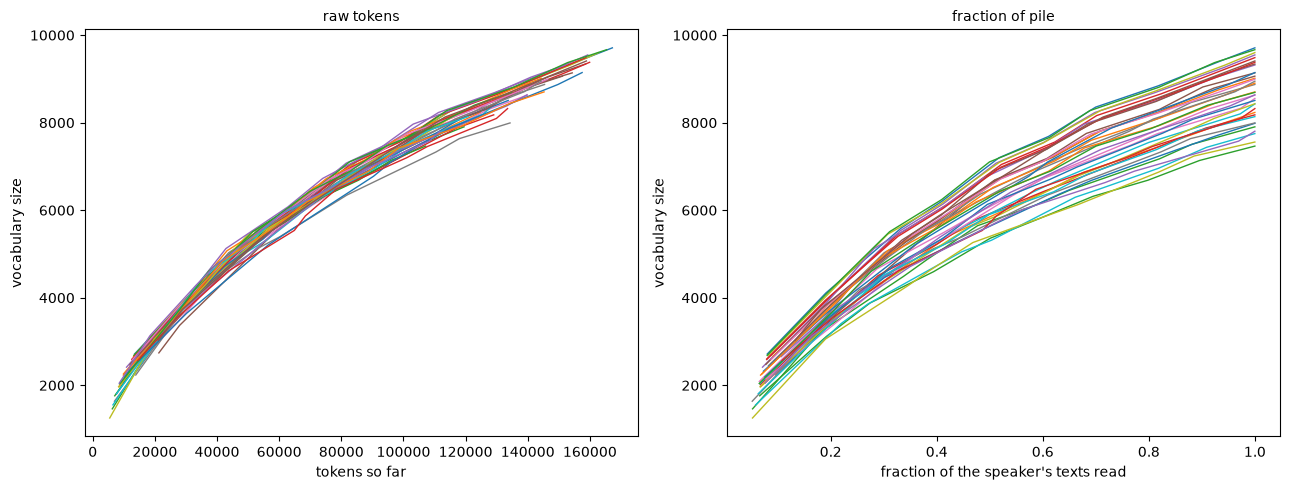

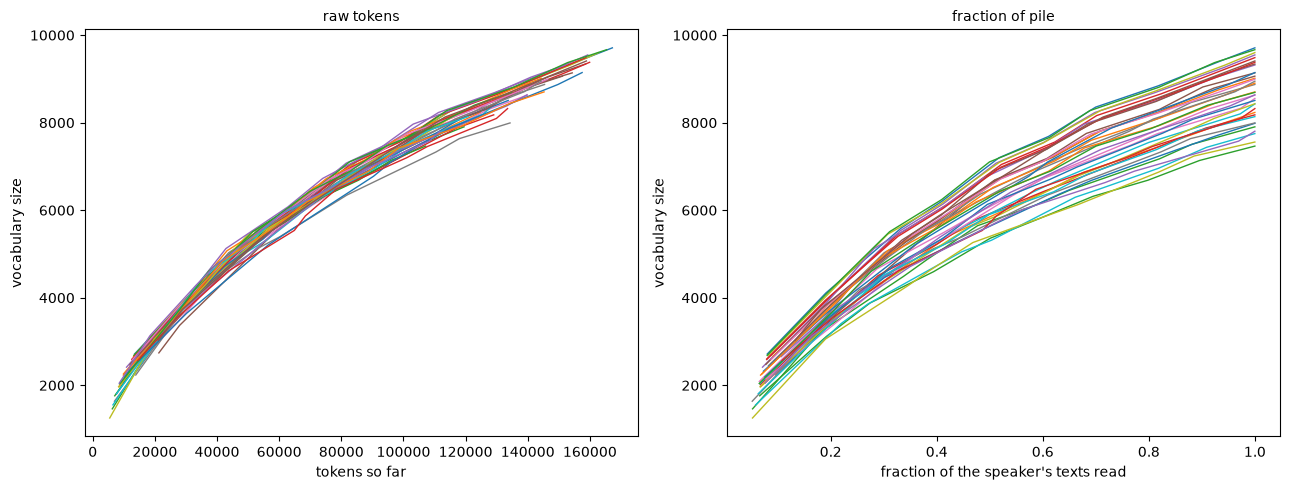

In [11]:
T2_FIG, (T2_AX1, T2_AX2) = plt.subplots(1, 2, figsize=(13, 5))
for _, pile_b in SPEAKERS.groupby("annotator"):
    growth = counting.vocab_growth(pile_b["english_item"])
    T2_AX1.plot(growth["tokens"], growth["vocab_size"], linewidth=1)
    # x as a share of the pile (0 to 1): the shape, not the length
    frac = growth["tokens"] / growth["tokens"].iloc[-1]
    T2_AX2.plot(frac, growth["vocab_size"], linewidth=1)
T2_AX1.set_title("raw tokens", fontsize=10)
T2_AX1.set_xlabel("tokens so far")
T2_AX1.set_ylabel("vocabulary size")
T2_AX2.set_title("fraction of pile", fontsize=10)
T2_AX2.set_xlabel("fraction of the speaker's texts read")
T2_AX2.set_ylabel("vocabulary size")
T2_FIG.tight_layout()
T2_FIG.savefig("outputs/figures/task2_vocab_growth.png", dpi=150)

T2_FIG

Curves bend flat early: ~20% in, most new words are found. The
shapes match across speakers. Vocabulary growth alone = a blunt
tool for separating personalities.

## (b) The topic robot (LDA): how many topic piles per speaker?

For every speaker we train one LDA per candidate topic count
(k = 3, 5, 8, 12, 16, 20) and grade the topic piles two ways:

- **coherence (c_v)**, blue, left axis: "do the piles make sense
  together?" Higher = better.
- **perplexity**, gray dashed, right axis: how sure the model is;
  higher (closer to 0) = better.

Coherence's peak = that speaker's best topic count. One panel per
speaker; results cached in `data/interim/lda/`.

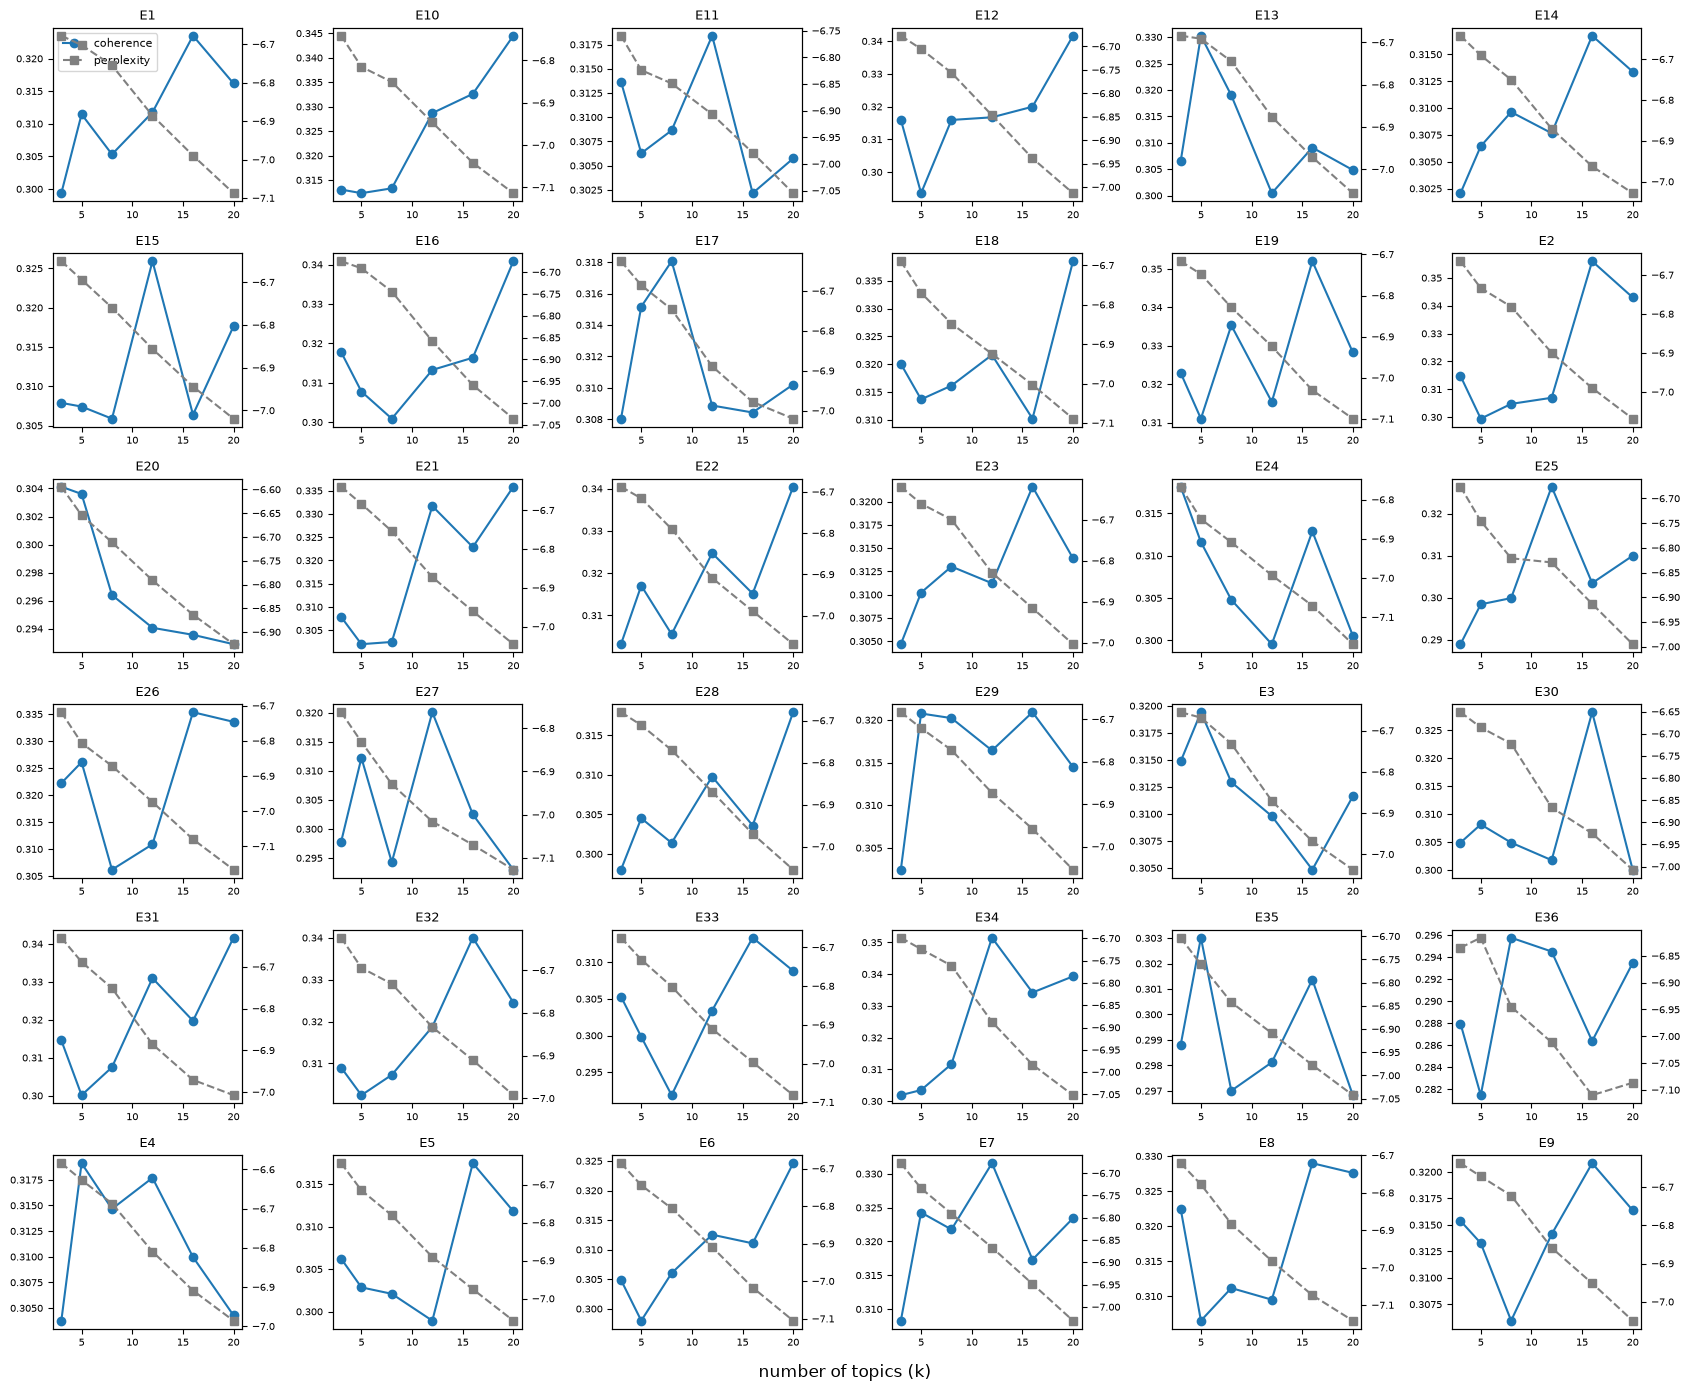

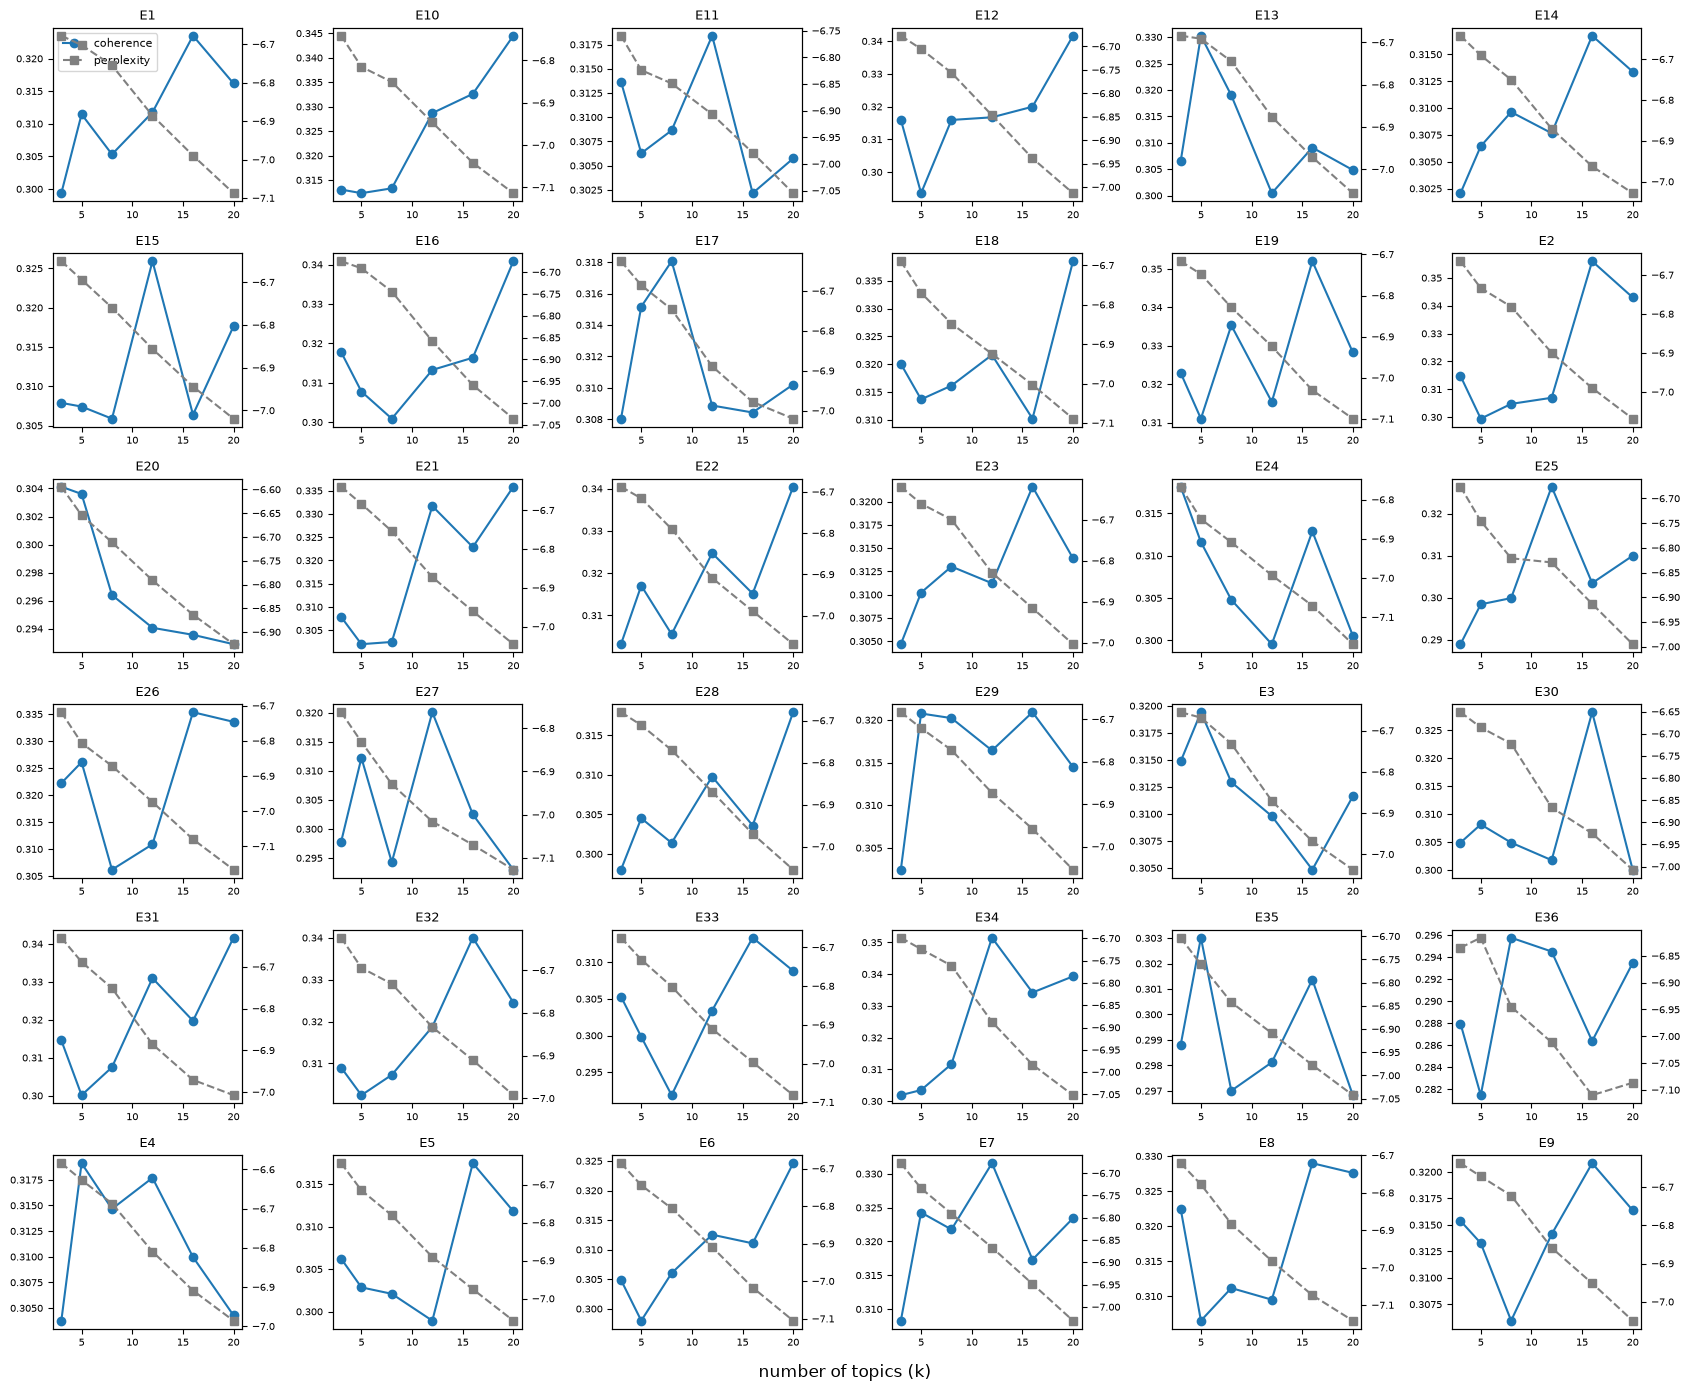

In [12]:
T2_SWEEPS = {}
T2_FIG2, T2_AXES = plt.subplots(6, 6, figsize=(17, 14))
for ax_b, (name_b, pile_c) in zip(T2_AXES.flat, SPEAKERS.groupby("annotator")):
    result = topics.sweep_speaker(name_b, pile_c["english_item"])
    T2_SWEEPS[name_b] = result
    # the right axis = the second scale: gray = perplexity
    ax2 = ax_b.twinx()
    l1 = ax_b.plot(result["k"], result["coherence"], "o-", label="coherence")
    l2 = ax2.plot(result["k"], result["perplexity"], "s--",
                  color="gray", label="perplexity")
    ax_b.set_title(name_b, fontsize=9)
    ax_b.tick_params(labelsize=7)
    ax2.tick_params(labelsize=7)
T2_AXES[0, 0].legend(l1 + l2, ["coherence", "perplexity"], fontsize=8)
T2_FIG2.supxlabel("number of topics (k)")
T2_FIG2.tight_layout()
T2_FIG2.savefig("outputs/figures/task2_lda_sweeps.png", dpi=150)

T2_FIG2

**What the grid says:** each person's "right number of topics" is
different, but the answer is not stable.

- Blue (coherence) is peaky: small values (0.30-0.34) with a
  visible peak per person, anywhere from k=3 to the range edge.
- Gray (perplexity) falls steadily for almost everyone: from the
  model's own view, *fewer* topics always fit better. The criteria
  disagree, so the "optimal k" = whichever one you trust.

In [13]:
T2_BEST = pd.DataFrame(
    {"best_k": {name2: topics.best_k(r) for name2, r in T2_SWEEPS.items()},
     "coherence": {name2: r["coherence"].max() for name2, r in T2_SWEEPS.items()}}
)
T2_TRAIT_COLS = ["Open.", "Cons.", "Extra.", "Agree.", "Neuro."]
T2_TRAIT_NAMES = ["openness", "conscientiousness", "extraversion",
               "agreeableness", "neuroticism"]
T2_TRAITS = (PROFILES.set_index("ID")[T2_TRAIT_COLS]
          .rename(columns=dict(zip(T2_TRAIT_COLS, T2_TRAIT_NAMES))))
T2_JOINED = T2_BEST.join(T2_TRAITS)
T2_CORR = (T2_JOINED.corr(method="spearman")
        .loc[T2_TRAIT_NAMES, ["best_k", "coherence"]])
T2_JOINED.to_csv("outputs/tables/task2_best_topics.csv")
T2_CORR.round(3).to_csv("outputs/tables/task2_trait_correlations.csv")

T2_BEST

,best_k,coherence
E1,16,0.323508
E10,20,0.344510
E11,12,0.318418
E12,20,0.341667
E13,5,0.330265
E14,16,0.316742
E15,12,0.325917
E16,20,0.340859
E17,8,0.318063
E18,20,0.338507


**What the best-k table says:** most speakers settle at many
topics: 13 of 36 at k=16, 9 at the boundary k=20, a few at k=3-8.
The spread itself (3-20) is the finding: people's piles genuinely
differ in how many themes run through them.

## Trait link

The table above lists each speaker's best topic count. Full tables:
`outputs/tables/task2_best_topics.csv` (with trait columns) and
`outputs/tables/task2_trait_correlations.csv` (Spearman).

In [14]:
T2_CORR

,best_k,coherence
openness,0.076659,-0.078634
conscientiousness,0.201144,-0.007604
extraversion,0.128243,0.170202
agreeableness,0.237605,0.021125
neuroticism,-0.190377,0.047920


**What the tie table says:** best-k climbs slightly with agreeableness
(+0.24) and conscientiousness (+0.20) and sinks a little with
neuroticism (−0.19); coherence itself ties to no trait at all. All
weak (n = 36), the same magnitude story as Task 1.

## Task 2 verdict

**(a)** Vocabulary growth cannot separate people: every curve bends
the same way, because everyone reads from the same event pool.
**(b)** Optimal topic counts do differ between speakers (k = 3-20),
but the ranking depends on the criterion: coherence favors many
topics, perplexity favors few, and boundary peaks suggest the range
is too small. Trait links stay weak (mildly agreeable and
conscientious speakers "hold more topics"). Same story as Task 1.

Weak spots: c_v coherence is noisy at 2 passes on ~2,500 short
texts; the texts are the events', not the speakers'; n = 36.

# 03 - Feeling words (Task 3)

Rule A piles (non-neutral reactions). Text column: `english_item`.
Dictionary: NRC VAD (valence, arousal, dominance).

In [15]:
# SETUP:
from personality import vad

SPEAKERS = data.load_speakers()
PROFILES = data.load_profiles()
VAD = vad.load_vad()

## VAD scores, per speaker

One row = one speaker (E1-E36). Scores come from NRC dictionary
hits in that speaker's pile, not from every token.

- **n_vad_hits**: how many tokens sat in the dictionary. The
  divider for the averages above.
- **valence**: pleasant (1) vs unpleasant (0).
- **arousal**: excited (1) vs calm (0).
- **dominance**: in control (1) vs overpowered (0).

For each dimension: the average, how much the scores wiggle, the
minimum, the maximum,
all over the hits only. Right side = their personality scores (0-1).

In [16]:
T3_ROWS = {
    name: vad.speaker_vad(pile["english_item"], VAD)
    for name, pile in SPEAKERS.groupby("annotator")
}
T3_STATS = pd.DataFrame(T3_ROWS).T
T3_STATS["n_vad_hits"] = T3_STATS["n_vad_hits"].astype(int)
T3_TRAIT_COLS = ["Open.", "Cons.", "Extra.", "Agree.", "Neuro."]
T3_TRAIT_NAMES = ["openness", "conscientiousness", "extraversion",
               "agreeableness", "neuroticism"]
T3_TRAITS = (PROFILES.set_index("ID")[T3_TRAIT_COLS]
          .rename(columns=dict(zip(T3_TRAIT_COLS, T3_TRAIT_NAMES))))
T3_JOINED = T3_STATS.join(T3_TRAITS)
T3_STATS.to_csv("outputs/tables/task3_speaker_vad.csv")

T3_JOINED

,n_vad_hits,valence_mean,valence_std,valence_min,valence_max,arousal_mean,arousal_std,arousal_min,arousal_max,dominance_mean,dominance_std,dominance_min,dominance_max,openness,conscientiousness,extraversion,agreeableness,neuroticism
E1,76509,0.603959,0.203926,0.0,1.0,0.440866,0.173133,0.069,0.99,0.524345,0.152867,0.045,0.983,0.698,0.646,0.604,0.740,0.417
E10,56958,0.602207,0.205196,0.0,1.0,0.441539,0.173818,0.069,0.99,0.522569,0.152338,0.045,0.991,0.781,0.573,0.396,0.854,0.844
E11,54218,0.602378,0.204170,0.0,1.0,0.439887,0.173931,0.069,0.99,0.520421,0.151634,0.045,0.981,0.760,0.781,0.646,0.802,0.188
E12,58599,0.604492,0.204392,0.0,1.0,0.439593,0.173309,0.069,0.99,0.520502,0.151570,0.045,0.991,0.344,0.531,0.646,0.604,0.594
E13,73064,0.603691,0.203696,0.0,1.0,0.440943,0.173387,0.069,0.99,0.524596,0.152873,0.045,0.991,0.562,0.625,0.625,0.573,0.448
E14,68651,0.605112,0.203706,0.0,1.0,0.439818,0.172574,0.069,0.99,0.523689,0.152969,0.045,0.991,0.865,0.906,0.583,0.604,0.396
E15,63495,0.603707,0.204594,0.0,1.0,0.440493,0.173804,0.069,0.99,0.520955,0.152004,0.045,0.991,0.698,0.562,0.583,0.875,0.552
E16,66169,0.602731,0.204694,0.0,1.0,0.440624,0.173319,0.069,0.99,0.522686,0.152409,0.045,0.983,0.677,0.844,0.656,0.833,0.198
E17,74710,0.603875,0.203977,0.0,1.0,0.441097,0.173196,0.069,0.99,0.524663,0.152939,0.045,0.991,0.625,0.552,0.427,0.510,0.844
E18,59166,0.601412,0.205374,0.0,1.0,0.441345,0.174475,0.069,0.99,0.522937,0.152856,0.045,0.991,0.760,0.906,0.667,0.792,0.177


**What the table says:** the feeling-word *level* barely moves;
the *pile* does.

- Valence means sit in a 0.597-0.607 band (about 1% spread).
- Arousal means: 0.437-0.444. Dominance means: 0.520-0.525.
  Same story: a tight band, not 36 different emotional palettes.
- Hits: 48k-77k. That range tracks pile size (Task 1 tokens), not a
  different dictionary habit.
- min/max = the scale's ends for everyone: the extremes live in
  the shared pool, so every pile finds them.

Feeling-word averages are even more alike than the Task 1 counts.
Any personality signal has to live in the small leftover variation.

## Mean valence, arousal, dominance by speaker

Three series, 36 speakers. x = speaker, y = mean score of dictionary
hits in that pile.

How to read it: height differences are the differences between
people. If the three lines are almost flat, the dictionary is
describing the *events*, not the people.

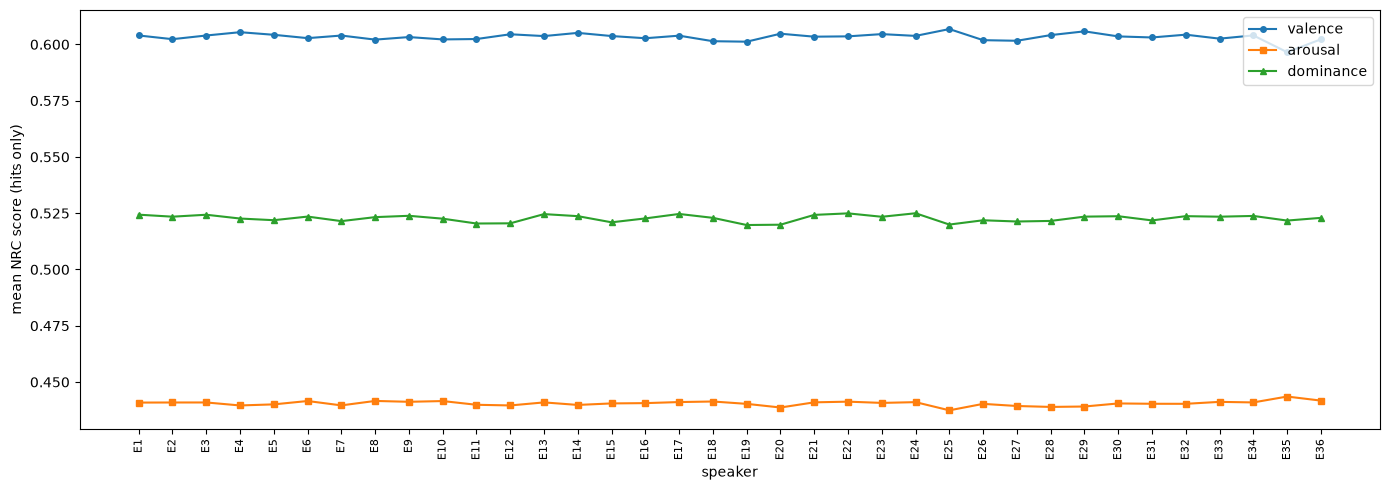

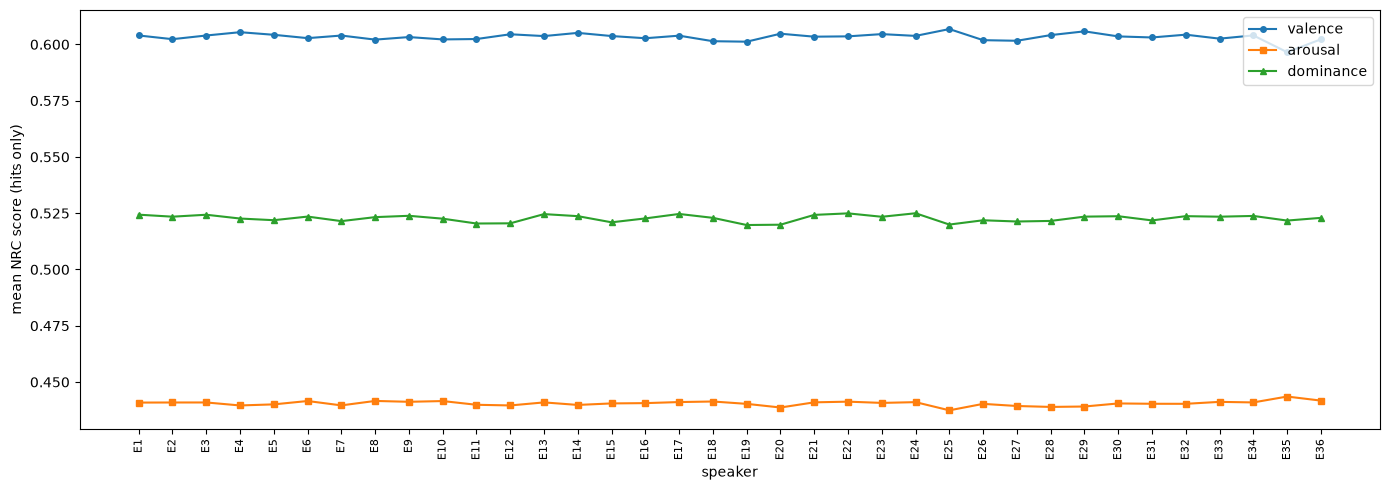

In [17]:
T3_ORDER = [f"E{n}" for n in range(1, 37)]
T3_PLOT = T3_STATS.reindex(T3_ORDER)
T3_FIG, T3_AX = plt.subplots(figsize=(14, 5))
T3_AX.plot(T3_PLOT.index, T3_PLOT["valence_mean"], "o-",
           label="valence", markersize=4)
T3_AX.plot(T3_PLOT.index, T3_PLOT["arousal_mean"], "s-",
           label="arousal", markersize=4)
T3_AX.plot(T3_PLOT.index, T3_PLOT["dominance_mean"], "^-",
           label="dominance", markersize=4)
T3_AX.set_ylabel("mean NRC score (hits only)")
T3_AX.set_xlabel("speaker")
T3_AX.tick_params(axis="x", labelsize=8, rotation=90)
T3_AX.legend()
T3_FIG.tight_layout()
T3_FIG.savefig("outputs/figures/task3_vad_means.png", dpi=150)

T3_FIG

**What the plot says:** three flat bands.

- Valence rides near 0.60, dominance near 0.52, arousal near 0.44.
  The gap *between* dimensions is larger than the gap *between*
  speakers.
- The wiggles are real but tiny: a few thousandths on a 0-1 scale.
- No speaker is a high-valence or high-arousal outlier. Under Rule A
  everyone is sampling the same English event texts; they only differ
  in *which* events they react to, and that is not enough to move
  the VAD means.

## Personality (annotator BFI, 0-1)

A **correlation table**. Question: *when a trait score is high, is
a VAD mean also high?*

- rows = the 5 personality traits.
- columns = the 3 VAD means.
- each cell = Spearman ρ from **−1 to +1**.

In [18]:
T3_MEAN_COLS = ["valence_mean", "arousal_mean", "dominance_mean"]
T3_CORR = (T3_JOINED[T3_MEAN_COLS + T3_TRAIT_NAMES]
        .corr(method="spearman")
        .loc[T3_TRAIT_NAMES, T3_MEAN_COLS])
T3_CORR.round(3).to_csv("outputs/tables/task3_trait_correlations.csv")
T3_CORR.round(2)

,valence_mean,arousal_mean,dominance_mean
openness,0.02,-0.12,0.01
conscientiousness,0.03,-0.12,0.10
extraversion,-0.14,-0.20,-0.16
agreeableness,-0.09,0.06,-0.15
neuroticism,-0.07,0.26,0.07


**What the correlation table says:** one modest tie, the rest noise.

- Neuroticism × arousal = +0.26 = the strongest cell. More emotional
  speakers' piles sit a little higher on arousal. Same direction as
  Task 1, likely the Rule A effect: they qualify more events.
- Extraversion: small negatives with all three means (−0.14 to
  −0.20). Agreeableness × dominance = −0.15.
- Openness and conscientiousness: ≈ 0 against valence; small
  negatives against arousal.

Magnitude check: max |r| = 0.26 at n = 36 is still a weak trend,
not a discriminator.

## Task 3 verdict

NRC VAD separates nobody. The three means sit a few thousandths
apart on the 0-1 scale; min/max are shared, because the dictionary
words live in the events. One weak tie: neuroticism-arousal, easy to
read as "who reacts to more events" rather than "who uses different
feeling words". The texts = the events' English, not the speakers'
own. n = 36.

## Outputs

- `outputs/tables/task3_speaker_vad.csv`: VAD mean/std/min/max and hits per speaker
- `outputs/tables/task3_trait_correlations.csv`: Spearman table
- `outputs/figures/task3_vad_means.png`: three mean series, 36 speakers

In [19]:
# SETUP:

from personality import buckets

SPEAKERS = data.load_speakers()
PROFILES = data.load_profiles()

In [20]:
T4_DOMINANT = buckets.dominant_traits(PROFILES)

T4_DOMINANT_COUNTS = (
    pd.Series(T4_DOMINANT)
    .value_counts()
    .reindex(buckets.TRAIT_NAMES, fill_value=0)
)

T4_DOMINANT_COUNTS

openness              3
conscientiousness    19
extraversion          2
agreeableness        10
neuroticism           2
Name: count, dtype: int64

In [21]:
T4_BUCKETS = buckets.bucket_speakers(SPEAKERS, PROFILES)

# rows become buckets; drop the unshown set column; keep whole numbers
T4_STATS = pd.DataFrame({
    trait: counting.speaker_stats(texts)
    for trait, texts in T4_BUCKETS.items()
}).T.drop(columns="vocabulary_set").astype(int)

T4_STATS

,vocabulary_size,tokens,repetitions,yes_words,no_words
openness,9887,454004,150996,670,6453
conscientiousness,9946,2677770,879068,3798,36954
extraversion,9678,287928,94453,416,4038
agreeableness,9945,1294653,423182,1852,17813
neuroticism,9828,303470,98929,443,4152


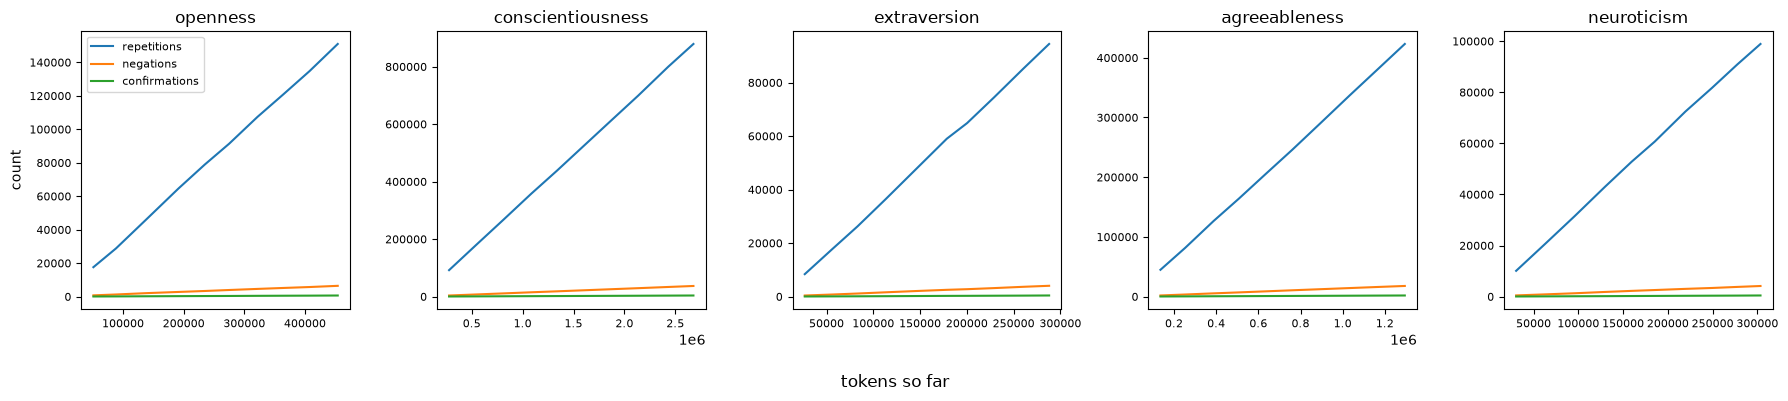

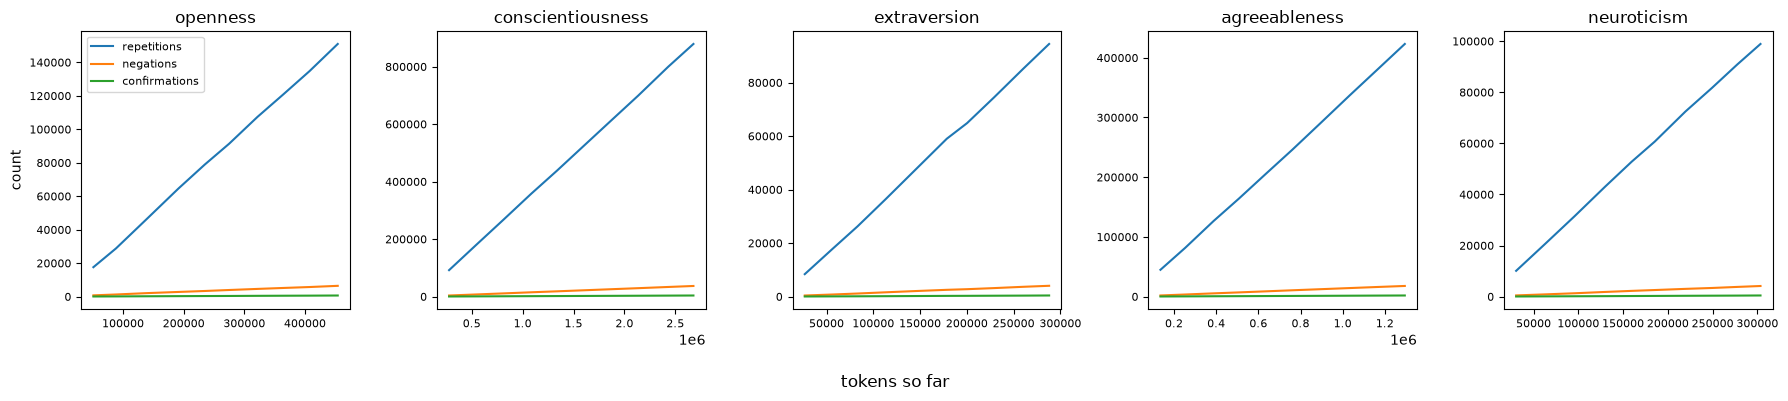

In [22]:
T4_FIG, T4_AXES = plt.subplots(1, 5, figsize=(18, 4), sharex=False)

for _ax, _trait in zip(T4_AXES, buckets.TRAIT_NAMES):
    _series = counting.chunked_series(T4_BUCKETS[_trait], chunks=10)

    _ax.plot(_series["tokens"], _series["repetitions"], label="repetitions")
    _ax.plot(_series["tokens"], _series["no_words"], label="negations")
    _ax.plot(_series["tokens"], _series["yes_words"], label="confirmations")

    _ax.set_title(_trait)
    _ax.tick_params(labelsize=8)

T4_AXES[0].set_ylabel("count")
T4_FIG.supxlabel("tokens so far")
T4_AXES[0].legend(fontsize=8)

T4_FIG.tight_layout()

T4_FIG

In [23]:
T4_STATS.to_csv("outputs/tables/task4_bucket_stats.csv")

T4_FIG.savefig(
    "outputs/figures/task4_bucket_evolution.png",
    dpi=150,
)

In [24]:
T4_NORMALIZED = T4_STATS.div(T4_STATS["tokens"], axis=0) * 1000
T4_NORMALIZED[["repetitions", "yes_words", "no_words"]]

,repetitions,yes_words,no_words
openness,332.587378,1.475758,14.213531
conscientiousness,328.283609,1.418344,13.800289
extraversion,328.043817,1.444806,14.024339
agreeableness,326.869053,1.430499,13.758899
neuroticism,325.992685,1.459782,13.681748


# 04 - Personality buckets (Task 4)

One bucket per speaker's strongest trait ("dominant"). The same
counting as Task 1, grouped by trait instead of person.

## Who is in which bucket

Dominant trait = the highest of their five profile scores.

## Counting each bucket

The same word counts as Task 1, over the bucket's texts. Raw totals
depend on the bucket size. Compare per 1,000 tokens (the table at
the end).

## Per-1,000-token rates

### Task 4 comment

**What this says.** The five buckets = nearly identical word rates:
326-333 repetitions; 1.42-1.48 yes-words; 13.68-14.21 no-words (per
1,000 tokens). Grouping by trait changes little.

**Weak spots.** The buckets = very uneven (19 people in
conscientiousness, 2 in extraversion). The smallest read as
anecdotes. The texts = the events' words, not the speakers' own.

# 05 - Personality meaning map (Task 5)

Each text = a point on a map of meanings; close points = similar
texts. That map = the meaning map. Doc2Vec draws the points;
cosine similarity = the twin-score (1 = twins, 0 = strangers).

One document per annotator (all their texts glued); its 4 pole-terms
per trait = the landmarks; the trait score = the biggest
twin-score; the highest trait = the prediction. Similarities are
not probabilities.

In [25]:
# SETUP:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from personality import embeddings

T5_SPEAKERS = data.load_speakers()
T5_PROFILES = data.load_profiles()

In [26]:
# Reference labels: each annotator's dominant personality trait.
T5_ACTUAL_TRAITS = buckets.dominant_traits(T5_PROFILES)

T5_ACTUAL = pd.Series(
    T5_ACTUAL_TRAITS,
    name="actual_trait",
    dtype="object",
)
T5_ACTUAL.index.name = "annotator"

# Use every valid, non-empty speaker text.
T5_VALID_SPEAKERS = T5_SPEAKERS.dropna(
    subset=["annotator", "english_item"]
).copy()

# force plain strings (some cells arrive as gaps); trim stray spaces
T5_VALID_SPEAKERS["annotator"] = (
    T5_VALID_SPEAKERS["annotator"].astype(str).str.strip()
)
T5_VALID_SPEAKERS["english_item"] = (
    T5_VALID_SPEAKERS["english_item"].astype(str).str.strip()
)

# drop rows with an empty annotator or empty text; renumber after
T5_VALID_SPEAKERS = T5_VALID_SPEAKERS[
    (T5_VALID_SPEAKERS["annotator"] != "")
    & (T5_VALID_SPEAKERS["english_item"] != "")
].reset_index(drop=True)

# show the row count at each step: the cut's cost
T5_DATA_SUMMARY = pd.DataFrame({
    "measure": [
        "All speaker rows",
        "Valid non-empty text rows",
        "Annotators with reference labels",
    ],
    "count": [
        len(T5_SPEAKERS),
        len(T5_VALID_SPEAKERS),
        len(T5_ACTUAL),
    ],
})

T5_DATA_SUMMARY

,measure,count
0,All speaker rows,90310
1,Valid non-empty text rows,90310
2,Annotators with reference labels,36


## Training + scoring (cached)

The model = trained on the pile texts + the pole terms (so the model
knows those words). The heavy part (train + per-speaker guesses)
runs once; later runs load:
`data/interim/task5_speaker_scores.parquet`. Rebuilding the cache
moves the Spearman values ~0.02. The numbers = the cache's, and
the cache = the record.

An honest baseline warning: a 50-dim Doc2Vec vs short term-words =
a weak probe. The next blocks say what it actually found.

In [27]:
from pathlib import Path

T5_SCORES_CACHE = Path("data/interim/task5_speaker_scores.parquet")
T5_COVERAGE_CACHE = Path("data/interim/task5_term_coverage.parquet")

# same numbers every run: load the saved scores, or train once and save
if T5_SCORES_CACHE.exists():
    T5_SPEAKER_SCORES = pd.read_parquet(T5_SCORES_CACHE)
    T5_TERM_COVERAGE = pd.read_parquet(T5_COVERAGE_CACHE)
    T5_TRAINING_SUMMARY = {"loaded": "from data/interim caches"}
else:
    T5_DEFINITION_TERMS = [
        term
        for terms in embeddings.TRAIT_TERMS.values()
        for term in terms
    ]

    T5_TRAIN_TEXTS = (
        T5_VALID_SPEAKERS["english_item"].tolist()
        + T5_DEFINITION_TERMS
    )

    T5_MODEL = embeddings.train_doc2vec(
        T5_TRAIN_TEXTS,
        vector_size=50,
        epochs=10,
        seed=42,
    )

    T5_TRAINING_SUMMARY = {
        "valid speaker text rows": len(T5_VALID_SPEAKERS),
        "definition terms added": len(T5_DEFINITION_TERMS),
        "training documents": len(T5_TRAIN_TEXTS),
        "vocabulary size": len(T5_MODEL.wv),
        "vector size": T5_MODEL.vector_size,
        "epochs": T5_MODEL.epochs,
    }

    T5_TERM_VECTORS = embeddings.score_traits(
        T5_MODEL,
        embeddings.TRAIT_TERMS,
    )

    T5_SPEAKER_TEXTS = (
        T5_VALID_SPEAKERS
        .groupby("annotator", sort=True)["english_item"]
        .agg(" ".join)
    )

    T5_SPEAKER_SCORES = embeddings.predict_traits(
        T5_MODEL,
        T5_SPEAKER_TEXTS.tolist(),
        T5_TERM_VECTORS,
    )
    T5_SPEAKER_SCORES.index = T5_SPEAKER_TEXTS.index

    T5_COVERAGE_ROWS = []
    for _trait, _terms in embeddings.TRAIT_TERMS.items():
        for _term in _terms:
            words = embeddings._tokens(_term)
            known_words = [
                word for word in words if word in T5_MODEL.wv
            ]
            T5_COVERAGE_ROWS.append({
                "trait": _trait,
                "definition_term": _term,
                "token_count": len(words),
                "known_token_count": len(known_words),
                "known_tokens": ", ".join(known_words),
                "covered": bool(known_words),
            })
    T5_TERM_COVERAGE = pd.DataFrame(T5_COVERAGE_ROWS)

    T5_SPEAKER_SCORES.to_parquet(T5_SCORES_CACHE)
    T5_TERM_COVERAGE.to_parquet(T5_COVERAGE_CACHE)

T5_TRAINING_SUMMARY

{'loaded': 'from data/interim caches'}

## Predictions

The model's trait per annotator, next to their real dominant trait.

In [28]:
T5_PREDICTED = embeddings.predict_labels(T5_SPEAKER_SCORES)

T5_RESULTS = pd.DataFrame({
    "actual_trait": T5_ACTUAL,
    "predicted_trait": T5_PREDICTED,
})

T5_RESULTS = T5_RESULTS.join(
    T5_SPEAKER_SCORES.add_prefix("similarity_"),
    how="left",
)
T5_RESULTS.index.name = "annotator"

T5_RESULTS

,actual_trait,predicted_trait,similarity_openness,similarity_conscientiousness,similarity_extraversion,similarity_agreeableness,similarity_neuroticism
annotator,,,,,,,
E1,agreeableness,neuroticism,0.552396,0.539539,0.466484,0.544737,0.618661
E10,agreeableness,neuroticism,0.504539,0.509602,0.433440,0.515083,0.582833
E11,agreeableness,neuroticism,0.527808,0.515307,0.399460,0.515578,0.594623
E12,extraversion,neuroticism,0.459239,0.455557,0.360056,0.480163,0.499874
E13,conscientiousness,neuroticism,0.578621,0.578805,0.482525,0.569147,0.636594
E14,conscientiousness,agreeableness,0.305873,0.349973,0.246600,0.358060,0.335665
E15,agreeableness,neuroticism,0.525527,0.506682,0.393160,0.531365,0.578757
E16,conscientiousness,neuroticism,0.471282,0.463168,0.384134,0.483840,0.510536
E17,neuroticism,neuroticism,0.560413,0.555695,0.534944,0.547445,0.627498


### Spearman correlation analysis

Does each trait's similarity track their real profile score?
Spearman compares the two, per trait:

- openness +0.104, conscientiousness -0.170, extraversion -0.197,
  agreeableness -0.035, neuroticism +0.221

Weak. Direction, not proof (n = 36; untested significance).

In [29]:
T5_BFI_COLUMNS = {
    "openness": "Open.",
    "conscientiousness": "Cons.",
    "extraversion": "Extra.",
    "agreeableness": "Agree.",
    "neuroticism": "Neuro.",
}

T5_BFI = T5_PROFILES.set_index("ID")
T5_ALIGNED_BFI = T5_BFI.reindex(T5_SPEAKER_SCORES.index)

T5_CORRELATION_ROWS = []

for T5_TRAIT, T5_BFI_COLUMN in T5_BFI_COLUMNS.items():
    T5_COMPARISON = pd.DataFrame({
        "similarity": T5_SPEAKER_SCORES[T5_TRAIT],
        "bfi_score": T5_ALIGNED_BFI[T5_BFI_COLUMN],
    }).dropna()

    T5_RHO = T5_COMPARISON["similarity"].corr(
        T5_COMPARISON["bfi_score"],
        method="spearman",
    )

    T5_CORRELATION_ROWS.append({
        "trait": T5_TRAIT,
        "bfi_column": T5_BFI_COLUMN,
        "n": len(T5_COMPARISON),
        "spearman_rho": T5_RHO,
    })

T5_SPEARMAN = pd.DataFrame(T5_CORRELATION_ROWS)

T5_SPEARMAN

,trait,bfi_column,n,spearman_rho
0,openness,Open.,36,0.104286
1,conscientiousness,Cons.,36,-0.169856
2,extraversion,Extra.,36,-0.196635
3,agreeableness,Agree.,36,-0.034521
4,neuroticism,Neuro.,36,0.221306


## Evaluation

Predictions are compared with the dominant personality labels
derived from the existing annotator profiles.

- **Accuracy:** how many guesses landed right.
- **Macro F1:** the average score across the five traits; each
  trait counts the same.
- **Uniform baseline:** expected accuracy of 20% when choosing uniformly
  among five traits.
- **Majority-class baseline:** accuracy obtained by always predicting
  the most common actual trait in the evaluation set.
- **Confusion matrix:** shows the actual and predicted trait counts.

These metrics measure agreement with the existing reference labels;
they do not establish that the model can reliably infer personality.
Baselines are important because a model can appear to make predictions
while performing worse than a simple majority-class rule.

In [30]:
T5_TRAIT_NAMES = [
    "openness",
    "conscientiousness",
    "extraversion",
    "agreeableness",
    "neuroticism",
]

T5_EVALUATION = T5_RESULTS.dropna(
    subset=["actual_trait", "predicted_trait"]
)

T5_Y_TRUE = T5_EVALUATION["actual_trait"]
T5_Y_PRED = T5_EVALUATION["predicted_trait"]

T5_ACCURACY = accuracy_score(T5_Y_TRUE, T5_Y_PRED)
T5_MACRO_F1 = f1_score(
    T5_Y_TRUE,
    T5_Y_PRED,
    labels=T5_TRAIT_NAMES,
    average="macro",
    zero_division=0,
)

T5_MAJORITY_BASELINE = (
    T5_Y_TRUE.value_counts(normalize=True).max()
    if len(T5_Y_TRUE)
    else float("nan")
)

T5_UNIFORM_BASELINE = 1 / len(T5_TRAIT_NAMES)

T5_METRICS = pd.DataFrame({
    "metric": [
        "evaluated_annotators",
        "accuracy",
        "macro_f1",
        "uniform_random_baseline",
        "majority_class_baseline",
    ],
    "value": [
        len(T5_EVALUATION),
        T5_ACCURACY,
        T5_MACRO_F1,
        T5_UNIFORM_BASELINE,
        T5_MAJORITY_BASELINE,
    ],
})

T5_CONFUSION = pd.DataFrame(
    confusion_matrix(
        T5_Y_TRUE,
        T5_Y_PRED,
        labels=T5_TRAIT_NAMES,
    ),
    index=T5_TRAIT_NAMES,
    columns=T5_TRAIT_NAMES,
)
T5_CONFUSION.index.name = "actual_trait"
T5_CONFUSION.columns.name = "predicted_trait"

T5_REPORT = pd.DataFrame(
    classification_report(
        T5_Y_TRUE,
        T5_Y_PRED,
        labels=T5_TRAIT_NAMES,
        output_dict=True,
        zero_division=0,
    )
).T

T5_METRICS

,metric,value
0,evaluated_annotators,36.000000
1,accuracy,0.111111
2,macro_f1,0.076190
3,uniform_random_baseline,0.200000
4,majority_class_baseline,0.527778


**What this says:** accuracy 11.1% (4/36) - below BOTH baselines
(uniform 20%, majority 52.78%). Predictions concentrate on
neuroticism (33/36 annotators in one column): the model still
distinguishes almost nothing, but the balanced pole lists removed
the one-trait-takes-all bias.

## Mean similarity by trait

Table + figure: the mean similarity per trait, and how much the
scores wiggle across annotators. Not probabilities.

In [31]:
T5_MEAN_SIMILARITY = pd.DataFrame({
    "trait": T5_TRAIT_NAMES,
    "mean_similarity": [
        T5_SPEAKER_SCORES[trait].mean()
        for trait in T5_TRAIT_NAMES
    ],
    "std_similarity": [
        T5_SPEAKER_SCORES[trait].std()
        for trait in T5_TRAIT_NAMES
    ],
})

T5_MEAN_SIMILARITY

,trait,mean_similarity,std_similarity
0,openness,0.507232,0.068732
1,conscientiousness,0.504953,0.055468
2,extraversion,0.419031,0.074399
3,agreeableness,0.517635,0.055725
4,neuroticism,0.562226,0.072400


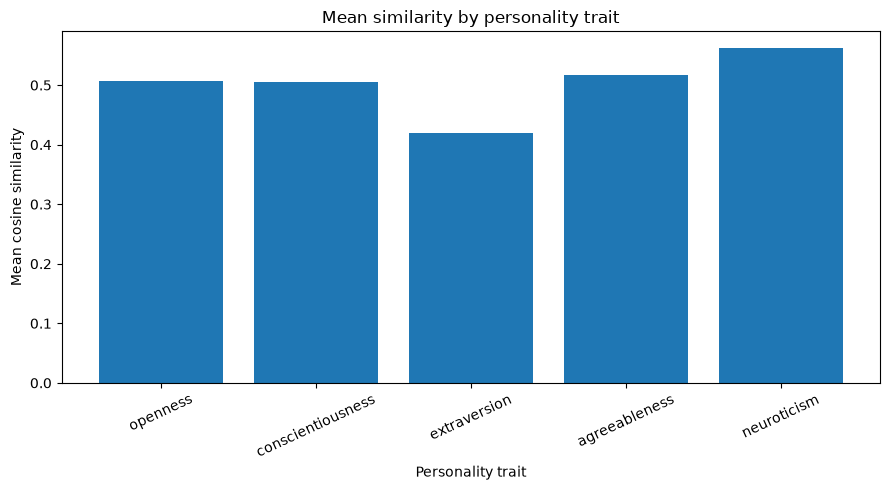

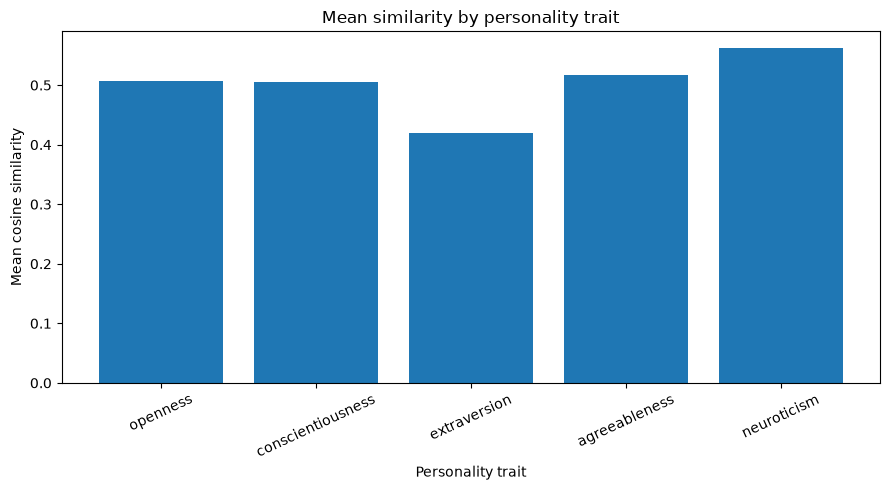

In [32]:
T5_SIM_FIG, T5_SIM_AX = plt.subplots(figsize=(9, 5))

T5_SIM_AX.bar(
    T5_MEAN_SIMILARITY["trait"],
    T5_MEAN_SIMILARITY["mean_similarity"],
)
T5_SIM_AX.set_title("Mean similarity by personality trait")
T5_SIM_AX.set_xlabel("Personality trait")
T5_SIM_AX.set_ylabel("Mean cosine similarity")
T5_SIM_AX.tick_params(axis="x", rotation=25)

T5_SIM_FIG.tight_layout()

T5_SIM_FIG

**What this says:** the five bars sit within a few hundredths of each
other - the cosine scores crowd together for every trait, which is
why the biggest-similarity choice barely separates anyone (and why
the winner can flip with small changes in the term lists).

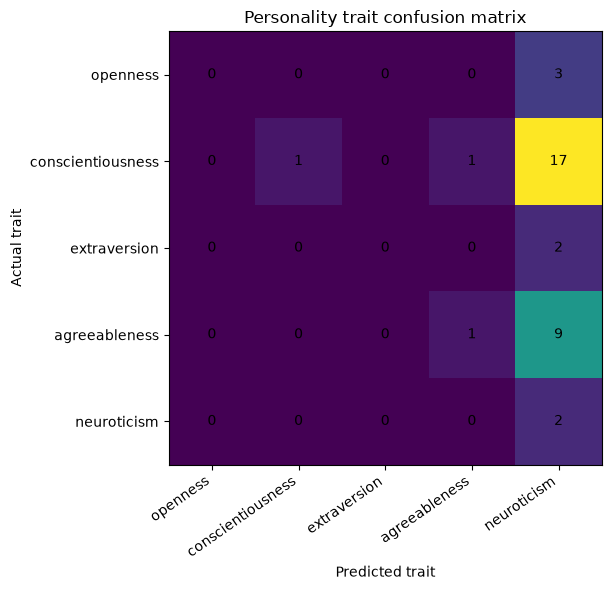

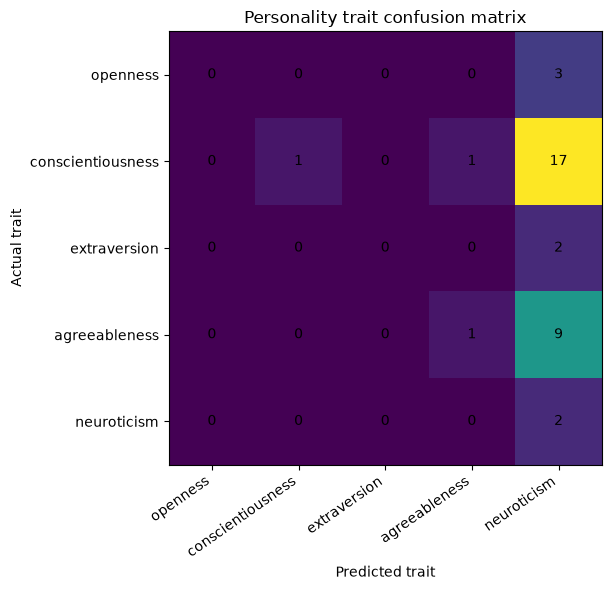

In [33]:
T5_CM_FIG, T5_CM_AX = plt.subplots(figsize=(8, 6))

T5_CM_AX.imshow(T5_CONFUSION.values)
T5_CM_AX.set_xticks(range(len(T5_CONFUSION.columns)))
T5_CM_AX.set_xticklabels(T5_CONFUSION.columns, rotation=35, ha="right")
T5_CM_AX.set_yticks(range(len(T5_CONFUSION.index)))
T5_CM_AX.set_yticklabels(T5_CONFUSION.index)

for row in range(len(T5_CONFUSION.index)):
    for col in range(len(T5_CONFUSION.columns)):
        T5_CM_AX.text(
            col,
            row,
            T5_CONFUSION.iloc[row, col],
            ha="center",
            va="center",
        )

T5_CM_AX.set_xlabel("Predicted trait")
T5_CM_AX.set_ylabel("Actual trait")
T5_CM_AX.set_title("Personality trait confusion matrix")

T5_CM_FIG.tight_layout()

T5_CM_FIG

**What this says:** the predicted column = one trait for (almost)
every annotator; the diagonal = the correct hits. Compare with the
52.78% majority-class baseline - the model distinguishes nothing.

## Definition-term coverage

Vocabulary check: does the model know at least one word of each
pole-term? A model that knows nobody's words cannot guess anybody's
trait. Coverage ≠ quality: knowing the words says nothing about the
guesses' sense.

In [34]:
T5_COVERAGE_SUMMARY = (
    T5_TERM_COVERAGE.groupby("trait", as_index=False)
    .agg(
        total_terms=("definition_term", "count"),
        covered_terms=("covered", "sum"),
    )
)

T5_COVERAGE_SUMMARY["coverage_percent"] = (
    100
    * T5_COVERAGE_SUMMARY["covered_terms"]
    / T5_COVERAGE_SUMMARY["total_terms"]
)

T5_TERM_COVERAGE

,trait,definition_term,token_count,known_token_count,known_tokens,covered
0,openness,intellectual,1,1,intellectual,True
1,openness,artistic,1,1,artistic,True
2,openness,imaginative,1,1,imaginative,True
3,openness,refined,1,1,refine,True
4,conscientiousness,responsible,1,1,responsible,True
5,conscientiousness,scrupulous,1,1,scrupulous,True
6,conscientiousness,persevering,1,1,persevere,True
7,conscientiousness,tidy,1,1,tidy,True
8,extraversion,talkative,1,1,talkative,True
9,extraversion,sociable,1,1,sociable,True


**What this says:** 20/20 pole-terms = known. The failure = the
scoring, not the vocabulary.

In [35]:
Path("outputs/tables").mkdir(parents=True, exist_ok=True)
Path("outputs/figures").mkdir(parents=True, exist_ok=True)

T5_RESULTS.to_csv("outputs/tables/task5_predictions.csv")
T5_METRICS.to_csv("outputs/tables/task5_metrics.csv", index=False)
T5_CONFUSION.to_csv("outputs/tables/task5_confusion_matrix.csv")
T5_REPORT.to_csv("outputs/tables/task5_classification_report.csv")
T5_MEAN_SIMILARITY.to_csv(
    "outputs/tables/task5_mean_similarity.csv", index=False
)
T5_SPEAKER_SCORES.to_csv(
    "outputs/tables/task5_speaker_similarity.csv"
)
T5_SPEARMAN.to_csv(
"outputs/tables/task5_spearman_correlations.csv",
index=False,
)
T5_TERM_COVERAGE.to_csv(
    "outputs/tables/task5_term_coverage.csv", index=False
)
T5_COVERAGE_SUMMARY.to_csv(
    "outputs/tables/task5_term_coverage_summary.csv", index=False
)

T5_SIM_FIG.savefig(
    "outputs/figures/task5_mean_similarity.png",
    dpi=150,
    bbox_inches="tight",
)
T5_CM_FIG.savefig(
    "outputs/figures/task5_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

"Task 5 outputs saved."

'Task 5 outputs saved.'

## Task 5 comment

**Setup.** The meaning map, one document per annotator, scored
against 4 pole-terms per trait; the biggest twin-score = the trait.
Model: a 50-dim Doc2Vec on our own event texts.

**Scores.** accuracy 11.1% (4/36); macro F1 0.076. Baselines:
uniform 20%, majority 52.8%. Spearman vs their real profiles: max
+0.22 (neuroticism).

**What this says.**

- The prediction = almost one trait for everyone (neuroticism,
  33/36). The balanced 4-pole lists removed the
  one-trait-takes-all bias, but the crowding remains.
- The similarity bars = crowded (all within a few hundredths):
  Doc2Vec's guesses sit near the pile-average; the biggest-similarity
  wins barely move.
- The Spearman story = weak in every direction. Nothing here
  tracks their real profiles.

**Verdict.** Meaning map fails as configured: an honest negative.
The paper's stronger setup (big models, 22-31% first-guesses) says
personality effects in language = small; a Doc2Vec probe this thin
never had a chance, and the vocab is complete (20/20). The loss =
the probe, not the words.

**Weak spots.** The texts = the events' words (the Rule A framing).
n = 36. The term lists' balance = itself a modeling choice. Full
detail lives in the blocks above; the report carries the
limitations.

# 06 - AI explanations (Task 6)

We give the AI measured numbers (similarity scores, personality
profile values and word statistics) and ask it to explain the choice.
It must not guess from text alone.

We select one case for each actual dominant trait, preferring wrong
predictions because they show where the method can mislead. Chosen
examples showing errors, not a fair sample.

The texts describe events that annotators reacted to; they did not
write the event texts themselves.

In [36]:
# SETUP:
import hashlib
import json


from personality.llm import PROMPT_VERSION, explain_trait

T6_PROFILES = data.load_profiles()
T6_SPEAKERS = data.load_speakers()

T6_TASK1 = pd.read_csv(
    "outputs/tables/task1_speaker_stats.csv",
    index_col=0,
)
T6_TASK3 = pd.read_csv(
    "outputs/tables/task3_speaker_vad.csv",
    index_col=0,
)
T6_TASK4 = pd.read_csv(
    "outputs/tables/task4_bucket_stats.csv",
    index_col=0,
)
T6_PREDICTIONS = pd.read_csv(
    "outputs/tables/task5_predictions.csv"
)
T6_SIMILARITY = pd.read_csv(
    "outputs/tables/task5_speaker_similarity.csv",
    index_col=0,
)

In [37]:
# Join the existing measurements by anonymized annotator ID.
# the CSV indexes arrive with stray spaces: make them plain strings
for T6_FRAME in (
    T6_TASK1,
    T6_TASK3,
    T6_TASK4,
    T6_SIMILARITY,
):
    T6_FRAME.index = T6_FRAME.index.astype(str).str.strip()

T6_PREDICTION_DATA = T6_PREDICTIONS.set_index("annotator")
T6_PREDICTION_DATA.index = (
    T6_PREDICTION_DATA.index.astype(str).str.strip()
)

T6_TRAITS = list(buckets.TRAIT_NAMES)
T6_SIM_COLUMNS = [f"similarity_{trait}" for trait in T6_TRAITS]

T6_ACTUAL = pd.Series(
    buckets.dominant_traits(T6_PROFILES),
    name="actual_trait",
)
T6_ACTUAL.index = T6_ACTUAL.index.astype(str).str.strip()

T6_PROFILE_RENAME = {
    "Open.": "profile_openness",
    "Cons.": "profile_conscientiousness",
    "Extra.": "profile_extraversion",
    "Agree.": "profile_agreeableness",
    "Neuro.": "profile_neuroticism",
}
T6_BFI = (
    T6_PROFILES.set_index("ID")[list(T6_PROFILE_RENAME)]
    .rename(columns=T6_PROFILE_RENAME)
)
T6_BFI.index = T6_BFI.index.astype(str).str.strip()

T6_CASES = (
    T6_PREDICTION_DATA[["actual_trait", "predicted_trait"]]
    .join(T6_SIMILARITY.add_prefix("similarity_"), how="inner")
    .join(T6_TASK1, how="left")
    .join(T6_TASK3, how="left")
    .join(T6_BFI, how="left")
)

T6_CASES["prediction_correct"] = (
    T6_CASES["actual_trait"] == T6_CASES["predicted_trait"]
)

# rank the five trait scores; keep the top two and the gap
def T6_score_summary(row):
    T6_RANKED = row[T6_SIM_COLUMNS].astype(float).sort_values(
        ascending=False
    )
    return pd.Series({
        "top_similarity_trait": T6_RANKED.index[0].replace(
            "similarity_", ""
        ),
        "top_similarity": T6_RANKED.iloc[0],
        "second_similarity": T6_RANKED.iloc[1],
        "score_margin": T6_RANKED.iloc[0] - T6_RANKED.iloc[1],
    })

T6_CASES = T6_CASES.join(
    T6_CASES.apply(T6_score_summary, axis=1)
)

# Normalize count measures so buckets of different sizes are comparable.
T6_BUCKET_RATES = T6_TASK4.copy()
T6_BUCKET_RATES["repetitions_per_1000"] = (
    1000 * T6_BUCKET_RATES["repetitions"] / T6_BUCKET_RATES["tokens"]
)
T6_BUCKET_RATES["confirmations_per_1000"] = (
    1000 * T6_BUCKET_RATES["yes_words"] / T6_BUCKET_RATES["tokens"]
)
T6_BUCKET_RATES["negations_per_1000"] = (
    1000 * T6_BUCKET_RATES["no_words"] / T6_BUCKET_RATES["tokens"]
)
T6_BUCKET_RATES = T6_BUCKET_RATES.reindex(T6_TRAITS)

# Select one case per actual trait. Prefer a wrong prediction,
# then a larger top-versus-second similarity margin.
T6_SELECTED_IDS = []
for T6_TRAIT in T6_TRAITS:
    T6_GROUP = T6_CASES[T6_CASES["actual_trait"] == T6_TRAIT]
    if T6_GROUP.empty:
        continue

    T6_WRONG = T6_GROUP[~T6_GROUP["prediction_correct"]]
    T6_CANDIDATES = T6_WRONG if not T6_WRONG.empty else T6_GROUP
    T6_CHOSEN = T6_CANDIDATES.sort_values(
        "score_margin", ascending=False
    ).head(1)
    T6_SELECTED_IDS.extend(T6_CHOSEN.index.tolist())

T6_SELECTED = T6_CASES.loc[T6_SELECTED_IDS].copy()

T6_SELECTED[
    [
        "actual_trait", "predicted_trait",
        "top_similarity_trait", "top_similarity",
        "second_similarity", "score_margin",
        "prediction_correct",
    ]
].round(3).reset_index()

,annotator,actual_trait,predicted_trait,top_similarity_trait,top_similarity,second_similarity,score_margin,prediction_correct
0,E3,openness,neuroticism,neuroticism,0.631,0.559,0.072,False
1,E22,conscientiousness,neuroticism,neuroticism,0.635,0.563,0.073,False
2,E9,extraversion,neuroticism,neuroticism,0.566,0.530,0.035,False
3,E10,agreeableness,neuroticism,neuroticism,0.583,0.515,0.068,False
4,E17,neuroticism,neuroticism,neuroticism,0.627,0.560,0.067,True


In [38]:
def T6_number(value):
    return round(float(value), 4) if pd.notna(value) else None

def T6_group_rates(trait):
    if trait not in T6_BUCKET_RATES.index:
        return {}
    return {
        name: T6_number(T6_BUCKET_RATES.loc[trait, name])
        for name in (
            "repetitions_per_1000",
            "confirmations_per_1000",
            "negations_per_1000",
        )
    }

# build the exact number dict the LLM will see, one per case
T6_EVIDENCE_BY_ID = {}

for T6_EVIDENCE_ANNOTATOR, T6_ROW in T6_SELECTED.iterrows():
    T6_PROFILE = {
        trait: T6_number(T6_ROW.get(f"profile_{trait}"))
        for trait in T6_TRAITS
    }
    T6_SIMILARITIES = {
        trait: T6_number(T6_ROW[f"similarity_{trait}"])
        for trait in T6_TRAITS
    }

    T6_PILE = T6_SPEAKERS.loc[
        T6_SPEAKERS["annotator"].astype(str) == str(T6_EVIDENCE_ANNOTATOR),
        "english_item",
    ]

    T6_EXAMPLES = []
    for T6_TEXT in T6_PILE.dropna().astype(str).drop_duplicates():
        T6_TEXT = " ".join(T6_TEXT.split())
        if T6_TEXT:
            T6_EXAMPLES.append(T6_TEXT[:220])
        if len(T6_EXAMPLES) == 2:
            break

    T6_EVIDENCE_BY_ID[str(T6_EVIDENCE_ANNOTATOR)] = {
        "annotator_id": str(T6_EVIDENCE_ANNOTATOR),
        "actual_dominant_trait": T6_ROW["actual_trait"],
        "task5_predicted_trait": T6_ROW["predicted_trait"],
        "highest_similarity_trait": T6_ROW["top_similarity_trait"],
        "top_similarity": T6_number(T6_ROW["top_similarity"]),
        "second_highest_similarity": T6_number(
            T6_ROW["second_similarity"]
        ),
        "top_score_margin": T6_number(T6_ROW["score_margin"]),
        "similarity_scores_not_probabilities": T6_SIMILARITIES,
        "big_five_profile_scores": T6_PROFILE,
        "task1_word_statistics": {
            "tokens": T6_number(T6_ROW.get("tokens")),
            "vocabulary_size": T6_number(T6_ROW.get("vocabulary_size")),
            "repetitions": T6_number(T6_ROW.get("repetitions")),
            "repetitions_per_1000": T6_number(
                1000 * T6_ROW["repetitions"] / T6_ROW["tokens"]
            ),
            "confirmations_per_1000": T6_number(
                1000 * T6_ROW["yes_words"] / T6_ROW["tokens"]
            ),
            "negations_per_1000": T6_number(
                1000 * T6_ROW["no_words"] / T6_ROW["tokens"]
            ),
        },
        "task3_vad_statistics": {
            name: T6_number(T6_ROW.get(name))
            for name in (
                "valence_mean", "valence_std",
                "arousal_mean", "arousal_std",
                "dominance_mean", "dominance_std",
            )
        },
        "task4_bucket_rates_per_1000_tokens": {
            "actual_trait_group": T6_group_rates(
                T6_ROW["actual_trait"]
            ),
            "predicted_trait_group": T6_group_rates(
                T6_ROW["predicted_trait"]
            ),
            "all_trait_groups": {
                trait: T6_group_rates(trait)
                for trait in T6_TRAITS
            },
        },
        "event_text_examples_not_authored_by_annotator": T6_EXAMPLES,
    }

In [39]:
T6_EVIDENCE_TABLE = T6_SELECTED[[
    "actual_trait",
    "predicted_trait",
    "top_similarity_trait",
    "top_similarity",
    "second_similarity",
    "score_margin",
    "prediction_correct",
    "tokens",
    "vocabulary_size",
    "valence_mean",
    "arousal_mean",
    "dominance_mean",
]].copy()

# Add per-annotator count rates (per 1,000 tokens) from Task 1.
T6_EVIDENCE_TABLE["repetitions_per_1000"] = (
    1000 * T6_SELECTED["repetitions"] / T6_SELECTED["tokens"]
)
T6_EVIDENCE_TABLE["confirmations_per_1000"] = (
    1000 * T6_SELECTED["yes_words"] / T6_SELECTED["tokens"]
)
T6_EVIDENCE_TABLE["negations_per_1000"] = (
    1000 * T6_SELECTED["no_words"] / T6_SELECTED["tokens"]
)
T6_EVIDENCE_TABLE = T6_EVIDENCE_TABLE.round(3).reset_index()

In [40]:
T6_EVIDENCE_TABLE

,annotator,actual_trait,predicted_trait,top_similarity_trait,top_similarity,second_similarity,score_margin,prediction_correct,tokens,vocabulary_size,valence_mean,arousal_mean,dominance_mean,repetitions_per_1000,confirmations_per_1000,negations_per_1000
0,E3,openness,neuroticism,neuroticism,0.631,0.559,0.072,False,165388,9667,0.604,0.441,0.524,329.552,1.409,13.876
1,E22,conscientiousness,neuroticism,neuroticism,0.635,0.563,0.073,False,152095,9318,0.604,0.441,0.525,329.084,1.414,13.649
2,E9,extraversion,neuroticism,neuroticism,0.566,0.530,0.035,False,158882,9410,0.603,0.441,0.524,328.451,1.416,13.752
3,E10,agreeableness,neuroticism,neuroticism,0.583,0.515,0.068,False,124707,8234,0.602,0.442,0.523,320.383,1.508,14.057
4,E17,neuroticism,neuroticism,neuroticism,0.627,0.560,0.067,True,162863,9601,0.604,0.441,0.525,325.765,1.412,13.932


**What the evidence table shows**

Four of five = misclassified; only E17 = correct. Neuroticism = the
top-similarity trait for all five. The margins: 0.0353 (E9,
weakest) to 0.0726 (E22).

Chosen cases (they show errors), not a fair sample. Actual traits =
the highest profile score; predicted traits = the twin-scores.
Similarities are not probabilities; a bigger margin = no guarantee.

**Re-runs reuse cached explanations.** Each answer is keyed by a
fingerprint of the inputs (its evidence + the prompt version).

Same inputs = the stored text. New evidence or an edited prompt
(version bumped) = fresh API calls.

The word count is recorded for each explanation, not enforced.

In [41]:
# Create the output directory next to the file write.
T6_OUTPUT_TABLES = Path("outputs/tables")
T6_OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)
T6_CACHE_PATH = T6_OUTPUT_TABLES / "task6_llm_explanations.csv"

# Cache successful responses so reruns do not repeat API requests.
T6_CACHE_BY_ID = {}

if T6_CACHE_PATH.exists():
    T6_OLD_CACHE = pd.read_csv(T6_CACHE_PATH).fillna("")
    T6_CACHE_BY_ID = {
        str(row["annotator"]): row.to_dict()
        for _, row in T6_OLD_CACHE.iterrows()
    }

T6_CURRENT_RESULTS = []

for T6_ANNOTATOR, T6_EVIDENCE in T6_EVIDENCE_BY_ID.items():
    T6_EVIDENCE_HASH = hashlib.sha256(
        json.dumps(
            T6_EVIDENCE,
            sort_keys=True,
            ensure_ascii=False,
        ).encode("utf-8")
    ).hexdigest()

    T6_OLD = T6_CACHE_BY_ID.get(T6_ANNOTATOR, {})
    T6_CACHE_VALID = (
        T6_OLD.get("prompt_version") == PROMPT_VERSION
        and T6_OLD.get("evidence_hash") == T6_EVIDENCE_HASH
        and T6_OLD.get("status") == "success"
        and bool(T6_OLD.get("explanation"))
    )

    if T6_CACHE_VALID:
        # Reuse the explanation and update its word count.
        T6_RESULT = T6_OLD.copy()
        T6_RESULT["word_count"] = len(
            str(T6_RESULT["explanation"]).split()
        )
        T6_CACHE_BY_ID[T6_ANNOTATOR] = T6_RESULT

    else:
        try:
            T6_RESPONSE = explain_trait(T6_EVIDENCE)
            T6_EXPLANATION = T6_RESPONSE["explanation"]

            T6_RESULT = {
                "annotator": T6_ANNOTATOR,
                "actual_trait": T6_EVIDENCE["actual_dominant_trait"],
                "predicted_trait": T6_EVIDENCE["task5_predicted_trait"],
                "score_margin": T6_EVIDENCE["top_score_margin"],
                "model": T6_RESPONSE["model"],
                "prompt_version": T6_RESPONSE["prompt_version"],
                "evidence_hash": T6_EVIDENCE_HASH,
                "explanation": T6_EXPLANATION,
                "word_count": len(T6_EXPLANATION.split()),
                "status": "success",
                "error": "",
            }

            # Save each successful response immediately.
            T6_CACHE_BY_ID[T6_ANNOTATOR] = T6_RESULT
            pd.DataFrame(T6_CACHE_BY_ID.values()).to_csv(
                T6_CACHE_PATH,
                index=False,
            )

        except RuntimeError as T6_ERROR:
            T6_RESULT = {
                "annotator": T6_ANNOTATOR,
                "actual_trait": T6_EVIDENCE["actual_dominant_trait"],
                "predicted_trait": T6_EVIDENCE["task5_predicted_trait"],
                "score_margin": T6_EVIDENCE["top_score_margin"],
                "model": "",
                "prompt_version": PROMPT_VERSION,
                "evidence_hash": T6_EVIDENCE_HASH,
                "explanation": "",
                "word_count": 0,
                "status": "error",
                "error": str(T6_ERROR),
            }

    T6_CURRENT_RESULTS.append(T6_RESULT)

# Persist word counts even if all explanations came from the cache.
pd.DataFrame(T6_CACHE_BY_ID.values()).to_csv(
    T6_CACHE_PATH,
    index=False,
)

T6_EXPLANATIONS = pd.DataFrame(T6_CURRENT_RESULTS)

T6_EXPLANATIONS[
    [
        "annotator",
        "actual_trait",
        "predicted_trait",
        "score_margin",
        "model",
        "prompt_version",
        "evidence_hash",
        "word_count",
        "status",
        "explanation",
        "error",
    ]
]

,annotator,actual_trait,predicted_trait,score_margin,model,prompt_version,evidence_hash,word_count,status,explanation,error
0,E3,openness,neuroticism,0.0719,nvidia/nemotron-3.5-super-vl:free,task6-evidence-v3,64a803cba39e04ff22e2956060426bd7ebb10a56c07a9f...,284,success,1. Prediction\nDoc2Vec selected neuroticism as...,
1,E22,conscientiousness,neuroticism,0.0726,nvidia/nemotron-3.5-super-vl:free,task6-evidence-v3,e88b33612b691495e91ca9f97b5daa121be55552bb9ae8...,217,success,1. Prediction\nDoc2Vec selected neuroticism as...,
2,E9,extraversion,neuroticism,0.0353,nvidia/nemotron-3.5-super-vl:free,task6-evidence-v3,9906c8c6bc4487a2b67e742c75edeece46d456956fb3a9...,217,success,1. Prediction\nDoc2Vec selected neuroticism as...,
3,E10,agreeableness,neuroticism,0.0678,nvidia/nemotron-3.5-super-vl:free,task6-evidence-v3,8c06f81040e99e8ce06fd0b13bec7241a06c1730dbee0d...,225,success,1. Prediction\nDoc2Vec selected neuroticism as...,
4,E17,neuroticism,neuroticism,0.0671,nvidia/nemotron-3.5-super-vl:free,task6-evidence-v3,0b8fcc1e63f78ededf33105975f39af692cea79dfbe8cd...,233,success,1. Prediction\nDoc2Vec selected neuroticism as...,


In [42]:
T6_SUCCEEDED = (
    int((T6_EXPLANATIONS["status"] == "success").sum())
    if not T6_EXPLANATIONS.empty else 0
)

mo.md(f"""
**LLM generation status:** {T6_SUCCEEDED} of
{len(T6_EXPLANATIONS)} selected explanations were generated successfully.

**Word-count check:** The prompt requests no more than 250 words.
The saved counts are E3: 284, E9: 217, E10: 225, E17: 233, and
E22: 217 words. E3 exceeds the requested limit. Counts are recorded
in the CSV, not enforced; longer responses are kept.

**What the LLM explanations show**

The explanations use the supplied similarity scores, Big Five
profiles, word statistics and VAD measurements to discuss supporting
evidence, counter-arguments and alternative interpretations.

All five cases received neuroticism as the predicted trait. Only E17
has neuroticism as its actual dominant trait.

The explanations provide a structured interpretation, but their
claims must be checked against the supplied measurements. A plausible
narrative is not evidence that a prediction is correct.

These explanations come after the prediction: they describe the
result, not what caused it. The LLM cannot inspect Doc2Vec's internal
computations or establish the causal reason for an individual prediction.
""")

_md()

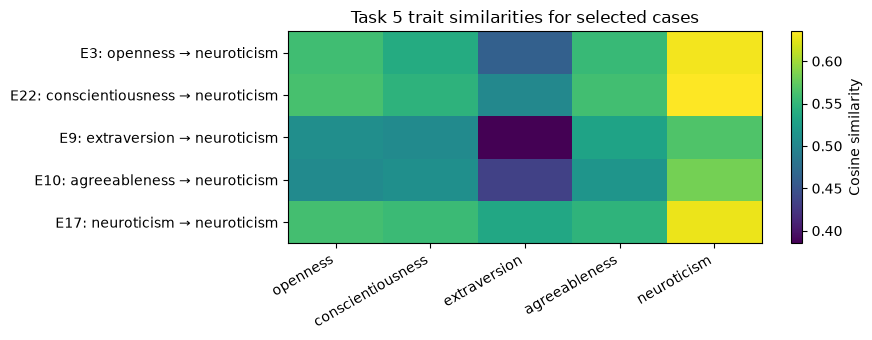

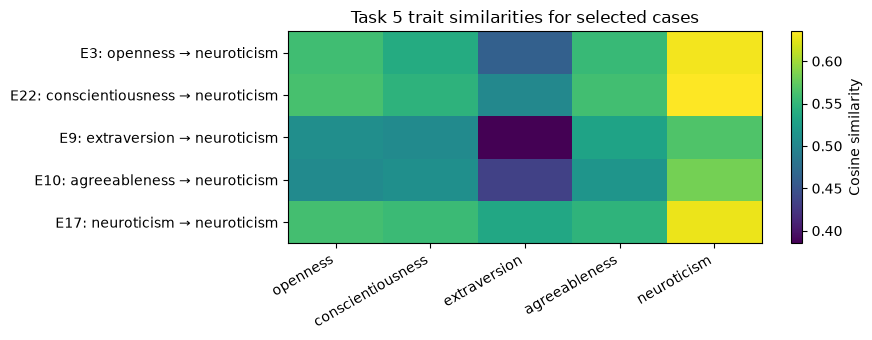

In [43]:
T6_HEAT_FIG, T6_HEAT_AX = plt.subplots(
    figsize=(9, max(3.5, 0.7 * len(T6_SELECTED)))
)
T6_HEAT_DATA = T6_SELECTED[T6_SIM_COLUMNS].astype(float).to_numpy()

T6_HEAT_IMAGE = T6_HEAT_AX.imshow(
    T6_HEAT_DATA, aspect="auto"
)
T6_HEAT_AX.set_xticks(range(len(T6_TRAITS)))
T6_HEAT_AX.set_xticklabels(T6_TRAITS, rotation=30, ha="right")
T6_HEAT_AX.set_yticks(range(len(T6_SELECTED)))
T6_HEAT_AX.set_yticklabels([
    f"{annotator}: {row.actual_trait} → {row.predicted_trait}"
    for annotator, row in T6_SELECTED.iterrows()
])
T6_HEAT_AX.set_title("Task 5 trait similarities for selected cases")
T6_HEAT_FIG.colorbar(
    T6_HEAT_IMAGE, ax=T6_HEAT_AX, label="Cosine similarity"
)
T6_HEAT_FIG.tight_layout()
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
T6_HEAT_FIG.savefig(
    Path("outputs/figures") / "task6_similarity_heatmap.png",
    dpi=150, bbox_inches="tight",
)

T6_HEAT_FIG

**What the similarity heatmap shows**

A twin-score per case: 1 = twins (same direction), 0 = strangers.
Not probabilities.

Neuroticism = the top score for all five; only E17 = actually
neurotic. The margins: E22 0.073 (largest), E9 0.035 (smallest).
A bigger margin = farther above the runner-up, not more correct.
The method favors neuroticism everywhere: read the rankings with
care.

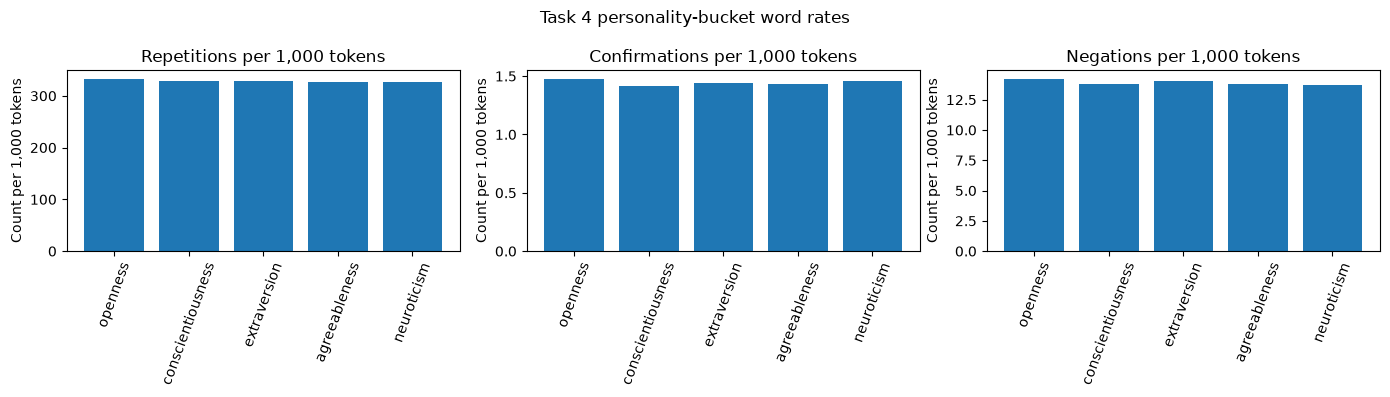

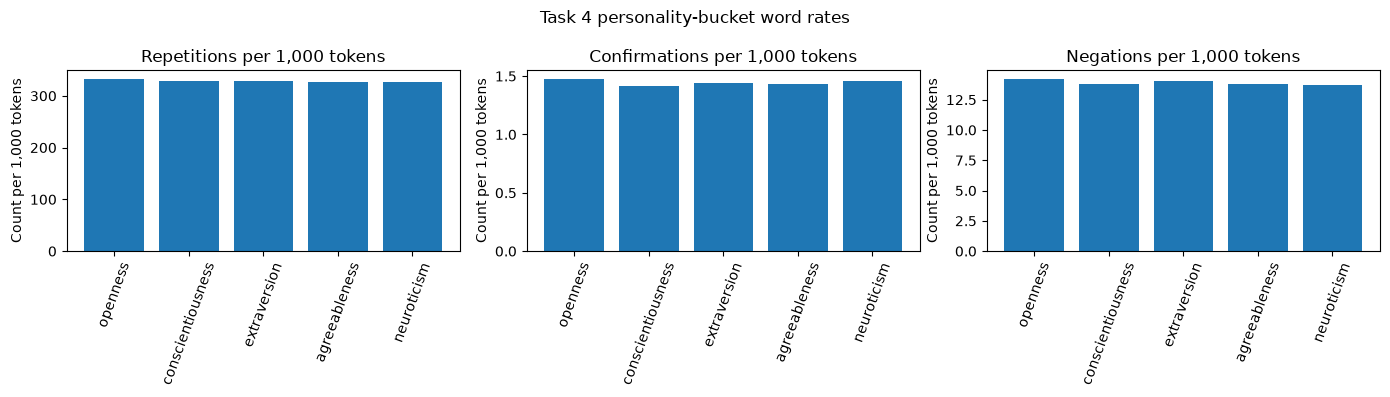

In [44]:
T6_RATE_COLUMNS = [
    ("repetitions_per_1000", "Repetitions per 1,000 tokens"),
    ("confirmations_per_1000", "Confirmations per 1,000 tokens"),
    ("negations_per_1000", "Negations per 1,000 tokens"),
]

T6_RATE_FIG, T6_RATE_AXES = plt.subplots(1, 3, figsize=(14, 4))

for T6_AX, (T6_COLUMN, T6_TITLE) in zip(
    T6_RATE_AXES, T6_RATE_COLUMNS
):
    T6_AX.bar(
        T6_BUCKET_RATES.index, T6_BUCKET_RATES[T6_COLUMN]
    )
    T6_AX.set_title(T6_TITLE)
    T6_AX.tick_params(axis="x", rotation=70)
    T6_AX.set_ylabel("Count per 1,000 tokens")

T6_RATE_FIG.suptitle("Task 4 personality-bucket word rates")
T6_RATE_FIG.tight_layout()
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
T6_RATE_FIG.savefig(
    Path("outputs/figures") / "task6_bucket_rates.png",
    dpi=150, bbox_inches="tight",
)

T6_RATE_FIG

**What the word-rate charts show**

Repetition rates range from 325.993 to 332.587 per 1,000 tokens.
Confirmation rates range from 1.418 to 1.476, and negation rates
range from 13.682 to 14.214.

The differences between the five personality-trait groups are small.
These word-count features provide limited descriptive evidence for
distinguishing the traits. Per-1,000-token rates make comparisons
fair; they do not establish significance.

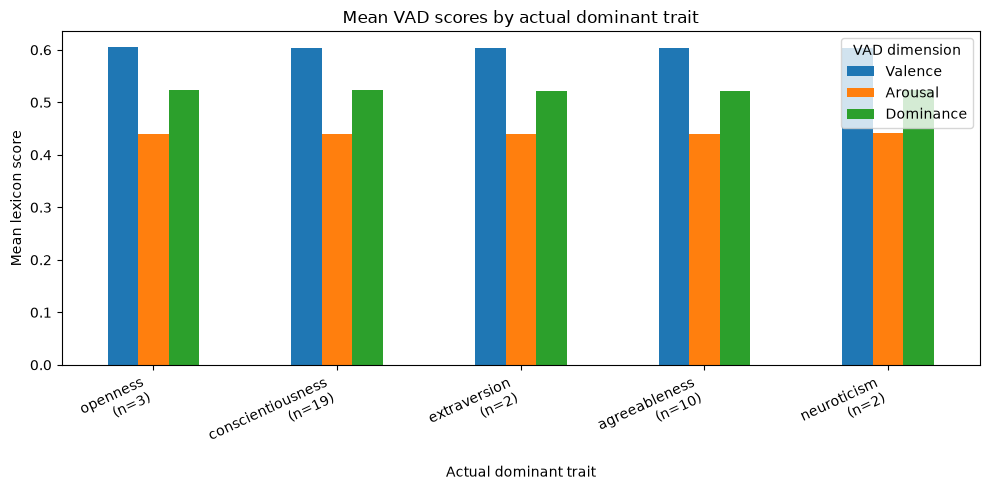

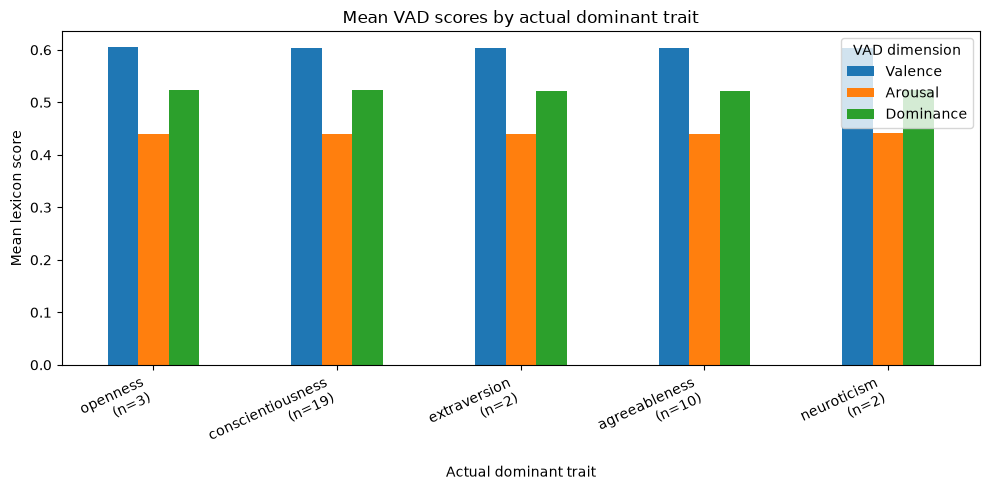

In [45]:
T6_VAD_COLUMNS = [
    "valence_mean",
    "arousal_mean",
    "dominance_mean",
]

# Use all annotators, not just the five selected examples.
T6_VAD_DATA = T6_TASK3.join(T6_ACTUAL, how="inner")

T6_VAD_BY_TRAIT = (
    T6_VAD_DATA.groupby("actual_trait")[T6_VAD_COLUMNS]
    .mean()
    .reindex(T6_TRAITS)
)

# Show the number of annotators in each trait group.
T6_VAD_COUNTS = (
    T6_VAD_DATA["actual_trait"]
    .value_counts()
    .reindex(T6_TRAITS, fill_value=0)
)

T6_VAD_FIG, T6_VAD_AX = plt.subplots(figsize=(10, 5))

T6_VAD_BY_TRAIT.rename(columns={
    "valence_mean": "Valence",
    "arousal_mean": "Arousal",
    "dominance_mean": "Dominance",
}).plot(kind="bar", ax=T6_VAD_AX)

T6_VAD_AX.set_title("Mean VAD scores by actual dominant trait")
T6_VAD_AX.set_xlabel("Actual dominant trait")
T6_VAD_AX.set_ylabel("Mean lexicon score")
T6_VAD_AX.set_xticklabels(
    [
        f"{trait}\n(n={T6_VAD_COUNTS[trait]})"
        for trait in T6_TRAITS
    ],
    rotation=25,
    ha="right",
)
T6_VAD_AX.legend(title="VAD dimension")
T6_VAD_FIG.tight_layout()

Path("outputs/figures").mkdir(parents=True, exist_ok=True)

T6_VAD_FIG.savefig(
    Path("outputs/figures") / "task6_vad_by_trait.png",
    dpi=150,
    bbox_inches="tight",
)

T6_VAD_FIG

**What the VAD chart shows**

All 36 annotators, per actual trait: valence 0.6027-0.6050, arousal
0.4396-0.4410, dominance 0.5218-0.5241. The averages crowd
together; no visible separation between the five groups. The
groups = uneven (19 conscientiousness, 10 agreeableness, 3
openness, 2 + 2 elsewhere): read with care.

The VAD averages do not distinguish the traits. The words = the
events', not their own; VAD describes the words, not direct
feelings.

## Task 6 comment

**Setup.** Task 5's predictions, explained by a cheap LLM (DeepSeek,
not the paper's model). Its input: only the measured numbers for the
five chosen cases. It never reads the texts.

**Scores.** Task 5 = 11.1% accuracy (4/36), below both baselines.
All five get neuroticism as the top similarity; only E17 = actually
neurotic. Margins 0.035-0.073. All five explanations generated; E3
returned 284 words (limit 250, recorded not enforced).

**What this says.** The LLM repeats the evidence back plausibly. But
the word rates and VAD averages barely move between trait groups:
the numbers carry almost no personality signal to find. Its
explanation describes the prediction; it cannot cause or validate
it.

**Verdict.** Good for reading the findings, not for proving them.

**Weak spots.** The texts = the events', not their own; the cases =
chosen to show errors, not a fair sample; n = 36. The report
carries the limitations.

## Outputs

- `outputs/tables/task6_llm_explanations.csv`: five explanations,
  including the model, prompt version, evidence hash, status and word count.
- `outputs/figures/task6_similarity_heatmap.png`: similarity scores
  for the selected cases.
- `outputs/figures/task6_bucket_rates.png`: word rates per 1,000
  tokens, by personality-trait group.
- `outputs/figures/task6_vad_by_trait.png`: average VAD scores by
  actual dominant trait, using all annotators with available measurements.

# 07 - The authors' method (Task 7)

The dataset authors' question, ours to reproduce: **given a person's
Big Five profile, how would they emotionally react to an event?**
Three ways of asking (no-persona / persona / persona + think step by
step), judged top-1 / top-2 against what the personality groups
actually answered. Our model = a free one: our numbers compare with
our baselines, their scores = a reference.

This notebook runs WITHOUT any model call: eval set + personas +
prompt examples only.

In [46]:
# SETUP:
from personality import env, llm

env.load_env()

T7_CONSENSUS_RAW = data.load_group_consensus()
T7_EVENTS = data.load_events()
T7_PROFILES = data.load_profiles()
T7_ANSWERS = pd.read_json(
    "data/interim/task7/answers.jsonl", lines=True
)
T7_POLAR = pd.read_json(
    "data/interim/task7/polarity.jsonl", lines=True
)

## The evaluation set (their two-criteria subset)

- consistent: every personality group answered with high internal
  agreement (consensus score > 40 of 100)

- diverging: the groups' majority answers are NOT all the same

Documented difference: the paper's exact divergence strength is not
fully specified against the released scores; our variant (threshold
40/100 + at least two distinct labels) = the closest match to their
published composition (469 events, mostly news - their 413: news
257 / social 69 / life 87).

In [47]:
T7_CONSENSUS_COLS = [f"g{n}_consensus_score" for n in range(1, 7)]
T7_EMO_COLS = [f"g{n}_emotion" for n in range(1, 7)]

T7_CONSISTENT = (T7_CONSENSUS_RAW[T7_CONSENSUS_COLS] > 40).all(axis=1)
T7_DIVERGING = T7_CONSENSUS_RAW[T7_EMO_COLS].nunique(axis=1) > 1

T7_SDS = T7_CONSENSUS_RAW[T7_CONSISTENT & T7_DIVERGING]

pd.DataFrame([
    ("all events", len(T7_CONSENSUS_RAW)),
    ("consistent (criterion 1)", int(T7_CONSISTENT.sum())),
    ("consistent + diverging (both criteria)", len(T7_SDS)),
    ("the paper's published subset size", 413),
], columns=["measure", "count"])

,measure,count
0,all events,3111
1,consistent (criterion 1),790
2,consistent + diverging (both criteria),469
3,the paper's published subset size,413


## The personas: one per personality group

Each group's persona = its members' average Big Five profile (the
group's average person), presented as the paper's persona block.

In [48]:
T7_MEMBERS = {
    f"g{n}": [m.strip() for m in str(
        T7_CONSENSUS_RAW.iloc[0][f"g{n}_members"]).split("/")]
    for n in range(1, 7)
}

T7_PERSONAS = llm.cluster_personas(
    T7_PROFILES.set_index("ID"), T7_MEMBERS
)

T7_PERSONAS

{'g1': 'A research-participant persona with the following Big Five inventory profile (0-1 scale): openness 0.82, conscientiousness 0.87, extraversion 0.69, agreeableness 0.62, neuroticism 0.36.',
 'g2': 'A research-participant persona with the following Big Five inventory profile (0-1 scale): openness 0.72, conscientiousness 0.54, extraversion 0.48, agreeableness 0.80, neuroticism 0.64.',
 'g3': 'A research-participant persona with the following Big Five inventory profile (0-1 scale): openness 0.55, conscientiousness 0.65, extraversion 0.63, agreeableness 0.67, neuroticism 0.43.',
 'g4': 'A research-participant persona with the following Big Five inventory profile (0-1 scale): openness 0.69, conscientiousness 0.83, extraversion 0.60, agreeableness 0.80, neuroticism 0.21.',
 'g5': 'A research-participant persona with the following Big Five inventory profile (0-1 scale): openness 0.56, conscientiousness 0.57, extraversion 0.45, agreeableness 0.58, neuroticism 0.59.',
 'g6': 'A research-p

## One worked example per strategy

In [49]:
# a real, short event text (event id 1180, news domain)
T7_EXAMPLE_EVENT = str(
    T7_EVENTS.set_index("id").loc[1180, "english_item"]
)

T7_EXAMPLES = pd.DataFrame([
    ("general (no personality)", llm.general_prompt(T7_EXAMPLE_EVENT)),
    ("persona (the group's average person)",
     llm.persona_prompt(T7_EXAMPLE_EVENT, T7_PERSONAS["g1"])),
    ("persona + step-by-step",
     llm.persona_prompt_cot(T7_EXAMPLE_EVENT, T7_PERSONAS["g1"])),
], columns=["strategy", "prompt"])

T7_EXAMPLES

,strategy,prompt
0,general (no personality),# SYSTEM ROLE\nYou are a general observer repr...
1,persona (the group's average person),# SYSTEM ROLE\nYou are a participant in a psyc...
2,persona + step-by-step,# SYSTEM ROLE\nYou are a participant in a psyc...


## Results: the three strategies vs the group answers

Answers come from the batch runner (`scripts/run_task7.py`, 100
seeded events x 6 groups x 3 strategies); this notebook reads the
cache. Accuracy compares each first/second guess with the group's
stored majority emotion. Baselines: uniform (1 in 7) and the most
frequent answer in the sample.

In [50]:
T7_OK = T7_ANSWERS[T7_ANSWERS["status"] == "ok"].copy()
# the stored key = "event_id|cluster|strategy"
T7_OK[["event_id", "cluster", "strategy"]] = (
    T7_OK["key"].str.split("|", expand=True)
)
T7_OK["event_id"] = T7_OK["event_id"].astype(int)

T7_LOOKUP = T7_CONSENSUS_RAW.set_index("id")
T7_OK["truth"] = [
    str(T7_LOOKUP.loc[e, f"{c}_emotion"])
    for e, c in zip(T7_OK["event_id"], T7_OK["cluster"])
]
T7_OK["source"] = [
    str(T7_LOOKUP.loc[e, "source"]) for e in T7_OK["event_id"]
]

# our extra test (one change at a time; no persona) ran once per
# event: broadcast each answer to the six groups' ground truths
T7_POLAR_ROWS = []
for _, _row in T7_POLAR[T7_POLAR["status"] == "ok"].iterrows():
    _event = int(_row["key"].split("|")[0])
    for _cluster in [f"g{n}" for n in range(1, 7)]:
        T7_POLAR_ROWS.append({
            "event_id": _event,
            "cluster": _cluster,
            "strategy": "polarity",
            "answer": _row["answer"],
            "truth": str(T7_LOOKUP.loc[_event, f"{_cluster}_emotion"]),
            "source": str(T7_LOOKUP.loc[_event, "source"]),
        })
T7_OK = pd.concat(
    [T7_OK, pd.DataFrame(T7_POLAR_ROWS)], ignore_index=True
)

T7_ROWS = []
for _strategy, _part in T7_OK.groupby("strategy"):
    T7_ROWS.append({
        "strategy": _strategy,
        "judgments": len(_part),
        "top1": llm.accuracy_top1(_part["answer"].tolist(),
                                 _part["truth"].tolist()),
        "top2": llm.accuracy_top2(_part["answer"].tolist(),
                                 _part["truth"].tolist()),
    })
T7_METRICS = pd.DataFrame(T7_ROWS)

T7_MAJORITY = T7_OK["truth"].value_counts(normalize=True).max()
T7_BASELINES = pd.DataFrame([
    ("uniform (1 in 7)", 1 / 7),
    ("most frequent answer", T7_MAJORITY),
], columns=["strategy", "top1"])

In [51]:
# which sources count as news or life; the rest = social
NEWS = {"ABC News", "BBC News", "Independent News",
        "Today's Headlines", "The Paper", "Weibo Trending Topics",
        "WeChat article"}
LIFE = {"FMylife", "BenignExistence", "IUTB"}

T7_DOMAIN_DATA = T7_OK.assign(domain=[
    "news" if s in NEWS else ("life" if s in LIFE else "social")
    for s in T7_OK["source"]
])

T7_DOMAIN_ROWS = []
for (_strategy, _domain), _part in T7_DOMAIN_DATA.groupby(
    ["strategy", "domain"]
):
    T7_DOMAIN_ROWS.append({
        "strategy": _strategy,
        "domain": _domain,
        "judgments": len(_part),
        "top1": _part["answer"].apply(
            lambda preds: preds[0]["Emotion"].lower()
        ).eq(_part["truth"].str.lower()).mean(),
    })
T7_BY_DOMAIN = pd.DataFrame(T7_DOMAIN_ROWS)

T7_BY_DOMAIN

,strategy,domain,judgments,top1
0,cot,life,84,0.571429
1,cot,news,348,0.477011
2,cot,social,166,0.554217
3,general,life,84,0.619048
4,general,news,344,0.494186
5,general,social,168,0.607143
6,persona,life,84,0.547619
7,persona,news,348,0.456897
8,persona,social,168,0.553571
9,polarity,life,84,0.619048


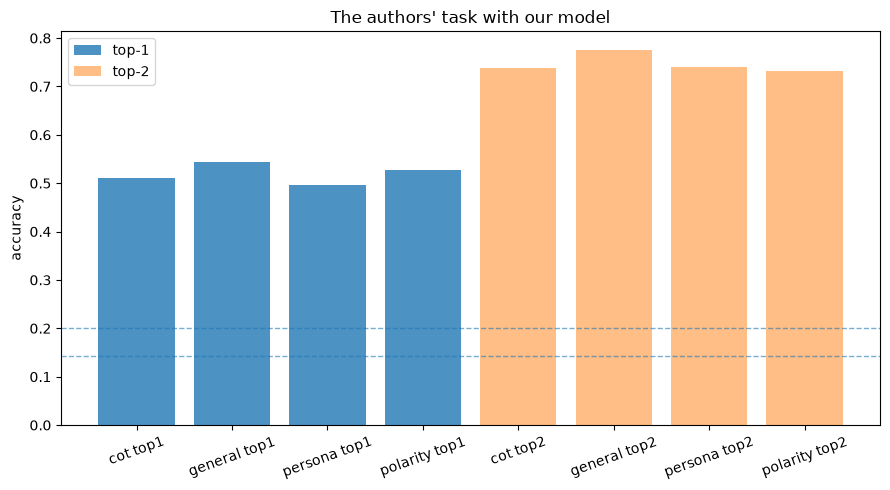

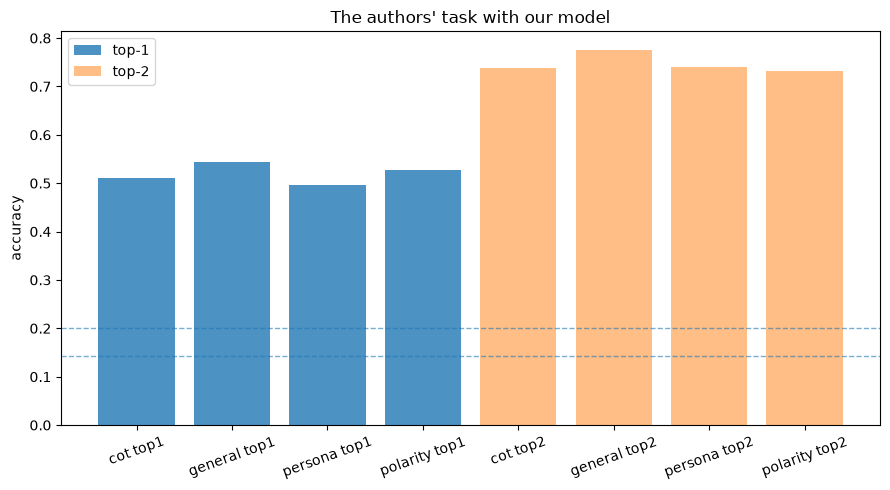

In [52]:

T7_ACC_FIG, T7_ACC_AX = plt.subplots(figsize=(9, 5))
T7_ACC_AX.bar(
    T7_METRICS["strategy"] + " top1", T7_METRICS["top1"],
    label="top-1", alpha=0.8,
)
T7_ACC_AX.bar(
    T7_METRICS["strategy"] + " top2", T7_METRICS["top2"],
    label="top-2", alpha=0.5,
)
for _name, _value in zip(T7_BASELINES["strategy"], T7_BASELINES["top1"]):
    T7_ACC_AX.axhline(_value, linestyle="--", linewidth=1, alpha=0.6)
T7_ACC_AX.set_ylabel("accuracy")
T7_ACC_AX.set_title("The authors' task with our model")
T7_ACC_AX.tick_params(axis="x", rotation=20)
T7_ACC_AX.legend()
T7_ACC_FIG.tight_layout()

Path("outputs/tables").mkdir(parents=True, exist_ok=True)
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
T7_METRICS.to_csv("outputs/tables/task7_metrics.csv", index=False)
T7_BASELINES.to_csv("outputs/tables/task7_baselines.csv", index=False)
T7_BY_DOMAIN.to_csv("outputs/tables/task7_by_domain.csv", index=False)
T7_ACC_FIG.savefig("outputs/figures/task7_accuracy.png", dpi=150)

T7_ACC_FIG

## Task 7 comment

**Setup.** Their task, our data: 100 events x 6 personality groups
x 3 of their prompts, plus one extra test of ours. Model: a cheap
DeepSeek (not theirs). Truth: each group's most common feeling.

**Scores (top-1 / top-2, ~600 tests each):**

- general (no personality): **54.4% / 77.5%**
- positive/negative first, no persona: 52.7% / 73.2%
- persona + think step by step: 51.2% / 73.9%
- persona: 49.7% / 74.0%
- baselines: uniform 14.3%, commonest answer 20.0%

**What this says.**

- All four beat the baselines hard. The model knows the obvious
  feeling of an easy event.
- Personality makes it WORSE. Plain prompt = best. Two reasons:
  our persona = an averaged person (faint signal), and our target =
  the group's most common answer (a persona can't move a group vote).
- Our extra test (say positive/negative first, no persona) scores
  like plain (52.7 vs 54.4) and beats persona. So the
  positive/negative step = harmless; the persona block = what costs
  points. Improvement attempt = a NEGATIVE result. Honest.
- News = hardest (46-49%). Social and life = easier (55-62%). The
  paper says social is hardest - our sample differs, so no match
  there.

**The paper comparison, honest.** Our ~50% is NOT their 22-31%.
Different tests: their sample = events where groups really DISAGREE
(hard). Ours = mostly events where groups AGREE (easy). Ours asks
"can you spot the obvious feeling?" Theirs asks "can you pick the
group's side when sides differ?" On easy events we beat baselines;
on hard events even their big models stay low.

**Weak spots.** Texts = the events' words, not the writers' own; 100
events per prompt; our model is not theirs; our subset is our
rebuilt version (documented above); 1,894 of 1,900 calls worked
(network/parse misses, retried).

## Outputs

- `outputs/tables/task7_metrics.csv`: accuracy per strategy
- `outputs/tables/task7_by_domain.csv`: the same, split by domain
- `outputs/figures/task7_accuracy.png`: the comparison chart
- answers cache: `data/interim/task7/answers.jsonl` (gitignored)